# Gelar Rasa 2026 
TIM : PNL- may i ngokang shotgun to ur place
- Dani Shofi Nur Izza
- Nino Ahmadiy
- Haidar Adlan Rozaq
UPN "Veteran Jawa Timur

## Ringkasan pipeline

| Tahap | Keputusan | Alasan |
|---|---|---|
| Audit & EDA | 1.920 train, 480 test, 0 file rusak; duplikat dipetakan | Mengetahui ukuran, format, duplikat, dan potensi leakage |
| Fitur | DINOv2 ViT-L/14 (self-supervised) + ConvNeXt-L (ImageNet-22k), TTA flip, L2-normalize |
| Validasi | 5 fold × 3 seed, grup duplikat tidak dipecah | Mencegah leakage gambar kembar |
| Klaster | KMeans k=64 pada fitur gabungan | Mengubah 1.920 gambar menjadi 64 klaster |
| Model | Logistic regression C=1, class_weight balanced | Baseline linear yang stabil dan mudah diaudit |
| Self-training | 2 iterasi, confidence ≥ 0.95, sepakat 3 seed | Memakai test tanpa label secara konservatif |
| Smoothing | kNN k=15, alpha=0.3 | Menghaluskan prediksi dengan struktur lokal |
| Output | `submissions.csv` | Submission deterministik dari prediksi yang dibekukan |



## Bab 0 — Config & Setup

In [1]:
# Install dependencies (dijalankan, bukan dilewati)
import sys
print("pip:", sys.executable, "-m pip")
!{sys.executable} -m pip install -q numpy pandas matplotlib pillow timm scikit-learn scipy
# torch/torchvision: index default mendukung CPU/CUDA (Linux) dan MPS (macOS).
# Jika grader memakai CUDA tertentu, ganti baris ini dengan index-url resmi PyTorch.
!{sys.executable} -m pip install -q torch torchvision


pip: /Users/macbookpro/Downloads/dsc-data-science-competition-gelar-rasa-2026/.venv/bin/python -m pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


In [2]:
# ============================================================
# BAB 0 — CONFIG & SETUP
# ============================================================
import os, sys, json, time, math, random, hashlib, platform, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
from PIL import Image, ImageOps

import torch
import torch.nn.functional as F
import timm
import sklearn
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import normalize

# ----------------------------
# Path & konstanta
# ----------------------------
def find_project_root(start: Path) -> Path:
    """Cari folder yang berisi dataset/SampleSubmission_DSC.csv."""
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "dataset" / "SampleSubmission_DSC.csv").exists():
            return p
    raise FileNotFoundError(
        "Root project tidak ditemukan. Jalankan notebook dari folder yang berisi dataset/."
    )

ROOT = find_project_root(Path.cwd())
DATA_DIR = ROOT / "dataset"
COMP_DIR = DATA_DIR / "Dataset DSC GelarRasa 2026"
TRAIN_DIR = COMP_DIR / "train"
TEST_DIR = COMP_DIR / "test"
SAMPLE_CSV = DATA_DIR / "SampleSubmission_DSC.csv"

ART_DIR = ROOT / "artifacts_nb"
LABEL_DIR = ROOT / "labeling"
SUB_DIR = ROOT / "submissions_nb"
for d in (ART_DIR, LABEL_DIR, SUB_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
CLASSES = ["glass", "paper", "electronic", "metal", "plastic", "cardboard", "textile", "foodwaste"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# Flag kerja berat
RUN_EXTRACT = True        # True: ekstraksi fitur jika cache belum ada
RUN_CLUSTER = True        # True: izin hitung ulang; file versi lama TIDAK ditimpa
RUN_STABILITY = True      # True: izin hitung ulang stabilitas; file versi lama TIDAK ditimpa
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
BATCH_SIZE = 4
NUM_WORKERS = 0           # Windows aman; naikkan hanya jika dataloader dipakai

# Desain eksperimen (revisi: k=64, tanpa gold set/label manual)
N_SPLITS = 5
CV_SEEDS = [0, 1, 2]
N_CLUSTERS = 64
K_GRID = [32, 64, 128]
N_KMEANS_SEEDS = [42, 43, 44]
CLUSTER_VERSION = "v1"
STABILITY_VERSION = "v1"
MAPPING_VERSION = "v1"
KNN_K = 15
SELF_TRAIN_CONF = 0.95
SMOOTH_ALPHA = 0.3
NEAR_DUP_COS = 0.95

RUN_TS = time.strftime("%Y%m%d_%H%M%S")
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# ----------------------------
# Helper kecil (dipakai bab berikutnya)
# ----------------------------
def require(cond, msg):
    """Assert dengan pesan yang menjelaskan tindakan yang harus dilakukan."""
    if not cond:
        raise AssertionError(msg)

def save_json(obj, path):
    path = Path(path)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def next_version_path(directory, stem, ext=".csv"):
    """Path versi berikutnya; tidak pernah menimpa file lama."""
    directory = Path(directory)
    p = directory / f"{stem}{ext}"
    if not p.exists():
        return p
    i = 2
    while (directory / f"{stem}_v{i}{ext}").exists():
        i += 1
    return directory / f"{stem}_v{i}{ext}"

def load_image(path):
    """Buka gambar, terapkan orientasi EXIF, lalu konversi ke RGB."""
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert("RGB")

def print_versions():
    import scipy
    rows = {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit-learn": sklearn.__version__,
        "scipy": scipy.__version__,
        "torch": torch.__version__,
        "timm": timm.__version__,
        "Pillow": Image.__version__,
        "matplotlib": matplotlib.__version__,
    }
    print(pd.DataFrame(rows.items(), columns=["library", "version"]).to_string(index=False))
    print(f"\nDEVICE = {DEVICE}")
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        print(f"GPU    = {p.name} | VRAM {p.total_memory/1e9:.2f} GB | CUDA {torch.version.cuda}")
    else:
        print("GPU    = tidak ada, berjalan di CPU")

print_versions()
print(f"\nROOT       = {ROOT}")
print(f"TRAIN_DIR  = {TRAIN_DIR}")
print(f"TEST_DIR   = {TEST_DIR}")
print(f"SEED       = {SEED} | folds = {N_SPLITS} x seeds {CV_SEEDS}")
print(f"RUN_EXTRACT= {RUN_EXTRACT} | RUN_CLUSTER = {RUN_CLUSTER} | RUN_STABILITY = {RUN_STABILITY} | BATCH_SIZE = {BATCH_SIZE}")

     library                      version
      python                      3.12.13
    platform macOS-26.5.2-arm64-arm-64bit
       numpy                        2.5.4
      pandas                        3.1.1
scikit-learn                        1.9.1
       scipy                       1.18.1
       torch                       2.15.0
        timm                       1.0.31
      Pillow                       13.0.0
  matplotlib                       3.11.2

DEVICE = mps
GPU    = tidak ada, berjalan di CPU

ROOT       = /Users/macbookpro/Downloads/dsc-data-science-competition-gelar-rasa-2026
TRAIN_DIR  = /Users/macbookpro/Downloads/dsc-data-science-competition-gelar-rasa-2026/dataset/Dataset DSC GelarRasa 2026/train
TEST_DIR   = /Users/macbookpro/Downloads/dsc-data-science-competition-gelar-rasa-2026/dataset/Dataset DSC GelarRasa 2026/test
SEED       = 42 | folds = 5 x seeds [0, 1, 2]
RUN_EXTRACT= True | RUN_CLUSTER = True | RUN_STABILITY = True | BATCH_SIZE = 4


In [3]:
# Snapshot config: file yang sama tidak ditimpa; jika isi berubah, tulis nama ber-hash.
CFG = {
    "seed": SEED,
    "classes": CLASSES,
    "n_splits": N_SPLITS,
    "cv_seeds": CV_SEEDS,
    "n_clusters": N_CLUSTERS,
    "k_grid": K_GRID,
    "n_kmeans_seeds": N_KMEANS_SEEDS,
    "cluster_version": CLUSTER_VERSION,
    "stability_version": STABILITY_VERSION,
    "mapping_version": MAPPING_VERSION,
    "knn_k": KNN_K,
    "self_train_conf": SELF_TRAIN_CONF,
    "smooth_alpha": SMOOTH_ALPHA,
    "near_dup_cosine": NEAR_DUP_COS,
    "device": DEVICE,
    "batch_size": BATCH_SIZE,
    "paths": {
        "train": str(TRAIN_DIR.relative_to(ROOT)),
        "test": str(TEST_DIR.relative_to(ROOT)),
        "sample": str(SAMPLE_CSV.relative_to(ROOT)),
        "artifacts": str(ART_DIR.relative_to(ROOT)),
        "labels": str(LABEL_DIR.relative_to(ROOT)),
        "submissions": str(SUB_DIR.relative_to(ROOT)),
    },
    "models": ["dinov2", "convnext"],
    "forbidden": ["clip", "siglip", "eva-clip", "open_clip", "llm", "automl"],
}

cfg_core = json.dumps(CFG, sort_keys=True)
cfg_path = ART_DIR / "run_config.json"
if cfg_path.exists():
    try:
        old = json.loads(cfg_path.read_text(encoding="utf-8"))
        old_core = json.dumps({k: v for k, v in old.items() if k != "written_at"}, sort_keys=True)
    except Exception:
        old_core = None
    if old_core != cfg_core:
        cfg_path = ART_DIR / f"run_config_{hashlib.md5(cfg_core.encode()).hexdigest()[:8]}.json"
save_json({"written_at": RUN_TS, **CFG}, cfg_path)

print("RINGKASAN BAB 0 - CONFIG")
print(f"- Root project : {ROOT}")
print(f"- Device       : {DEVICE}" + (" (GPU CUDA terdeteksi)" if DEVICE == "cuda" else (" (Apple MPS terdeteksi)" if DEVICE == "mps" else " (CPU; ekstraksi fitur akan lambat)")))
print(f"- Kelas (8)    : {', '.join(CLASSES)}")
print(f"- Seed utama   : {SEED}; seed repeated CV: {CV_SEEDS}")
print(f"- Snapshot     : {cfg_path.relative_to(ROOT)}")
print("- Gate 0      : LULUS - path, kelas, seed, dan device siap.")
print("Risiko: jika notebook dijalankan di mesin lain, cache fitur harus ada atau RUN_EXTRACT=True.")

RINGKASAN BAB 0 - CONFIG
- Root project : /Users/macbookpro/Downloads/dsc-data-science-competition-gelar-rasa-2026
- Device       : mps (Apple MPS terdeteksi)
- Kelas (8)    : glass, paper, electronic, metal, plastic, cardboard, textile, foodwaste
- Seed utama   : 42; seed repeated CV: [0, 1, 2]
- Snapshot     : artifacts_nb/run_config.json
- Gate 0      : LULUS - path, kelas, seed, dan device siap.
Risiko: jika notebook dijalankan di mesin lain, cache fitur harus ada atau RUN_EXTRACT=True.


## Bab 1 — Audit Data & EDA

**Tujuan:** memastikan data terbaca, mapping test 1:1 dengan sample submission, dan menemukan duplikat/ukuran/format yang memengaruhi preprocessing dan validasi.

In [4]:
# ----------------------------
# 1.1 File inventory & mapping test
# ----------------------------
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

train_files = sorted([p for p in TRAIN_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXT])
test_files = sorted([p for p in TEST_DIR.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXT])

require(len(train_files) == 1920, f"Train harus 1.920 gambar, ditemukan {len(train_files)}. Periksa TRAIN_DIR.")
require(len(test_files) == 480, f"Test harus 480 gambar, ditemukan {len(test_files)}. Periksa TEST_DIR.")

train_df = pd.DataFrame({"filename": [p.name for p in train_files], "path": train_files})
train_df["image_id"] = train_df.filename.map(lambda x: Path(x).stem)

# Hanya image_id yang dibaca. waste_category diabaikan.
sample_ids = pd.read_csv(SAMPLE_CSV, usecols=["image_id"], dtype={"image_id": str}, encoding="utf-8-sig")
sample_ids["image_id"] = sample_ids["image_id"].astype(str).str.strip().str.zfill(3)
require(sample_ids.image_id.is_unique, "image_id di sample submission tidak unik.")
require(len(sample_ids) == 480, f"Sample submission harus 480 baris, ditemukan {len(sample_ids)}.")

by_stem = {p.stem: p for p in test_files}
require(len(by_stem) == len(test_files), "Ada nama file test duplikat setelah menghapus ekstensi.")

missing = sorted(set(sample_ids.image_id) - set(by_stem))
extra = sorted(set(by_stem) - set(sample_ids.image_id))
require(not missing, f"ID sample tanpa file test: {missing[:10]} ...")
require(not extra, f"File test tanpa ID sample: {extra[:10]} ...")

test_df = pd.DataFrame({"image_id": sample_ids.image_id.tolist()})
test_df["path"] = test_df.image_id.map(by_stem)
test_df["filename"] = test_df.path.map(lambda p: p.name)
require(test_df.path.notna().all(), "Mapping test gagal: ada path kosong.")

print(f"Train : {len(train_df)} file")
print(f"Test  : {len(test_df)} file | mapping 1:1 dengan sample submission")
print(f"Contoh train: {train_df.filename.head(3).tolist()} ... {train_df.filename.tail(2).tolist()}")
print(f"Contoh test : {test_df.filename.head(3).tolist()} ... {test_df.filename.tail(2).tolist()}")

Train : 1920 file
Test  : 480 file | mapping 1:1 dengan sample submission
Contoh train: ['0001.jpg', '0002.jpg', '0003.jpg'] ... ['1919.jpg', '1920.jpg']
Contoh test : ['001.jpg', '002.jpg', '003.jpg'] ... ['479.jpg', '480.jpg']


In [5]:
# ----------------------------
# 1.2 Manifest: ukuran, format, EXIF, hash piksel
# ----------------------------
def audit_one(path: Path) -> dict:
    """Baca satu gambar; catat ukuran setelah EXIF transpose dan hash piksel RGB."""
    with Image.open(path) as im:
        fmt = im.format
        try:
            orientation = int(im.getexif().get(274, 1))
        except Exception:
            orientation = 1
        im2 = ImageOps.exif_transpose(im).convert("RGB")
        arr = np.asarray(im2)
        h, w = arr.shape[:2]
        digest = hashlib.md5(arr.tobytes()).hexdigest()
    return {
        "width": int(w),
        "height": int(h),
        "mode": "RGB",
        "format": fmt or path.suffix.upper().lstrip("."),
        "file_bytes": int(path.stat().st_size),
        "exif_orientation": orientation,
        "pixel_hash": digest,
    }

def compute_manifest() -> pd.DataFrame:
    rows = []
    for split, df in [("train", train_df), ("test", test_df)]:
        for i, row in df.iterrows():
            rec = {"split": split, "filename": row["filename"], "path": str(Path(row["path"]).relative_to(ROOT))}
            try:
                rec.update(audit_one(Path(row["path"])))
                rec["error"] = ""
            except Exception as e:
                rec.update({"width": np.nan, "height": np.nan, "mode": "", "format": "",
                            "file_bytes": np.nan, "exif_orientation": np.nan, "pixel_hash": "",
                            "error": repr(e)})
            rows.append(rec)
    return pd.DataFrame(rows)

def manifest_is_valid(df: pd.DataFrame) -> bool:
    need = {"split", "filename", "path", "width", "height", "pixel_hash", "error"}
    if not need.issubset(df.columns):
        return False
    tr = df[df.split == "train"].filename.tolist()
    te = df[df.split == "test"].filename.tolist()
    return tr == train_df.filename.tolist() and te == test_df.filename.tolist() and (df.error.fillna("") == "").all()

manifest_path = ART_DIR / "audit_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path, dtype={"pixel_hash": str, "error": str})
    if manifest_is_valid(manifest):
        print(f"Manifest dimuat dari cache: {manifest_path.relative_to(ROOT)}")
    else:
        backup = ART_DIR / f"audit_manifest_old_{RUN_TS}.csv"
        manifest_path.replace(backup)
        print(f"Cache manifest tidak valid; file lama dipindah ke {backup.name}. Menghitung ulang...")
        manifest = compute_manifest()
        manifest.to_csv(manifest_path, index=False)
else:
    print("Menghitung manifest 2.400 gambar (sekali saja; hasil di-cache)...")
    t0 = time.time()
    manifest = compute_manifest()
    manifest.to_csv(manifest_path, index=False)
    print(f"Selesai dalam {time.time()-t0:.1f} detik: {manifest_path.relative_to(ROOT)}")

require(len(manifest) == 2400, f"Manifest harus 2.400 baris, ditemukan {len(manifest)}.")
require((manifest.error.fillna("") == "").all(), "Ada gambar yang gagal dibaca. Cek kolom error di audit_manifest.csv.")

# ----------------------------
# 1.3 Duplikat piksel
# ----------------------------
dups = manifest[manifest.pixel_hash.duplicated(keep=False)].sort_values(["pixel_hash", "split", "filename"]).copy()
dup_groups = (dups.groupby("pixel_hash")
              .agg(n_files=("filename", "size"),
                   splits=("split", lambda s: "+".join(sorted(set(s)))),
                   files=("filename", lambda s: ";".join(s)))
              .reset_index())
n_dup_files = len(dups)
n_dup_groups = len(dup_groups)

train_test_pairs = []
for h, sub in dups.groupby("pixel_hash"):
    tr = sub[sub.split == "train"].filename.tolist()
    te = sub[sub.split == "test"].filename.tolist()
    for a in tr:
        for b in te:
            train_test_pairs.append({"train_filename": a, "test_filename": b, "pixel_hash": h})
train_test_pairs = pd.DataFrame(train_test_pairs, columns=["train_filename", "test_filename", "pixel_hash"])

dups.to_csv(ART_DIR / "exact_duplicates.csv", index=False)
train_test_pairs.to_csv(ART_DIR / "train_test_exact_pairs.csv", index=False)

# ----------------------------
# 1.4 Statistik ukuran & format
# ----------------------------
stats_rows = []
for split in ["train", "test"]:
    d = manifest[manifest.split == split]
    ar = d.width / d.height
    mp = d.width * d.height / 1e6
    stats_rows.append({
        "split": split, "n": len(d),
        "width_min": d.width.min(), "width_median": d.width.median(), "width_max": d.width.max(),
        "height_min": d.height.min(), "height_median": d.height.median(), "height_max": d.height.max(),
        "aspect_min": ar.min(), "aspect_median": ar.median(), "aspect_max": ar.max(),
        "megapixel_median": mp.median(),
    })
stats = pd.DataFrame(stats_rows).set_index("split")

print("\nStatistik ukuran (setelah EXIF transpose):")
print(stats.round(2).to_string())
print("\nFormat PIL :", manifest.format.value_counts().to_dict())
print("Ekstensi   :", manifest.filename.str.lower().str.rsplit(".", n=1).str[-1].value_counts().to_dict())
print(f"\nDuplikat piksel: {n_dup_files} file dalam {n_dup_groups} grup")
if n_dup_groups:
    print(dup_groups[["n_files", "splits", "files"]].head(10).to_string(index=False))
print(f"Pasangan duplikat train-test: {len(train_test_pairs)}")
if len(train_test_pairs):
    print(train_test_pairs.head(10).to_string(index=False))

gate1 = (
    len(train_df) == 1920 and len(test_df) == 480
    and (manifest.error.fillna("") == "").all()
    and set(test_df.image_id) == set(sample_ids.image_id)
)
print(f"\nGate 1 (audit): {'LULUS' if gate1 else 'GAGAL'}")
require(gate1, "Gate 1 gagal. Periksa path, file rusak, atau mapping test.")

Manifest dimuat dari cache: artifacts_nb/audit_manifest.csv

Statistik ukuran (setelah EXIF transpose):
          n  width_min  width_median  width_max  height_min  height_median  height_max  aspect_min  aspect_median  aspect_max  megapixel_median
split                                                                                                                                          
train  1920        100         509.0       2605         100          485.5        4032        0.56            1.0        2.85              0.21
test    480        129         416.0       1600         168          416.0        1167        0.33            1.0        2.11              0.17

Format PIL : {'JPEG': 2397, 'PNG': 3}
Ekstensi   : {'jpg': 2293, 'jpeg': 106, 'png': 1}

Duplikat piksel: 8 file dalam 4 grup
 n_files     splits             files
       2 test+train  017.jpg;1046.jpg
       2 test+train  201.jpg;1135.jpg
       2 test+train  042.jpg;1821.jpg
       2      train 0848.jpg;1717.jpg
Pas

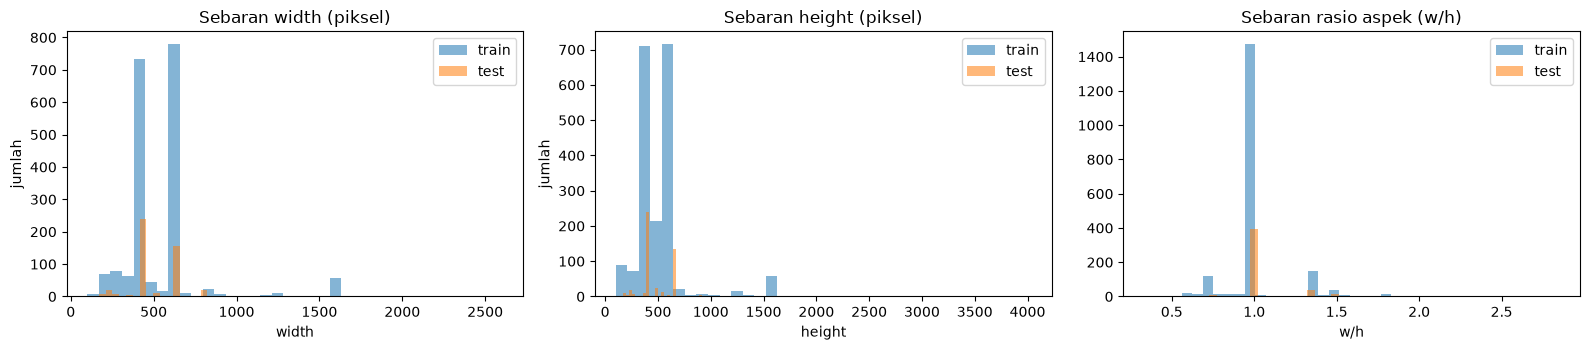

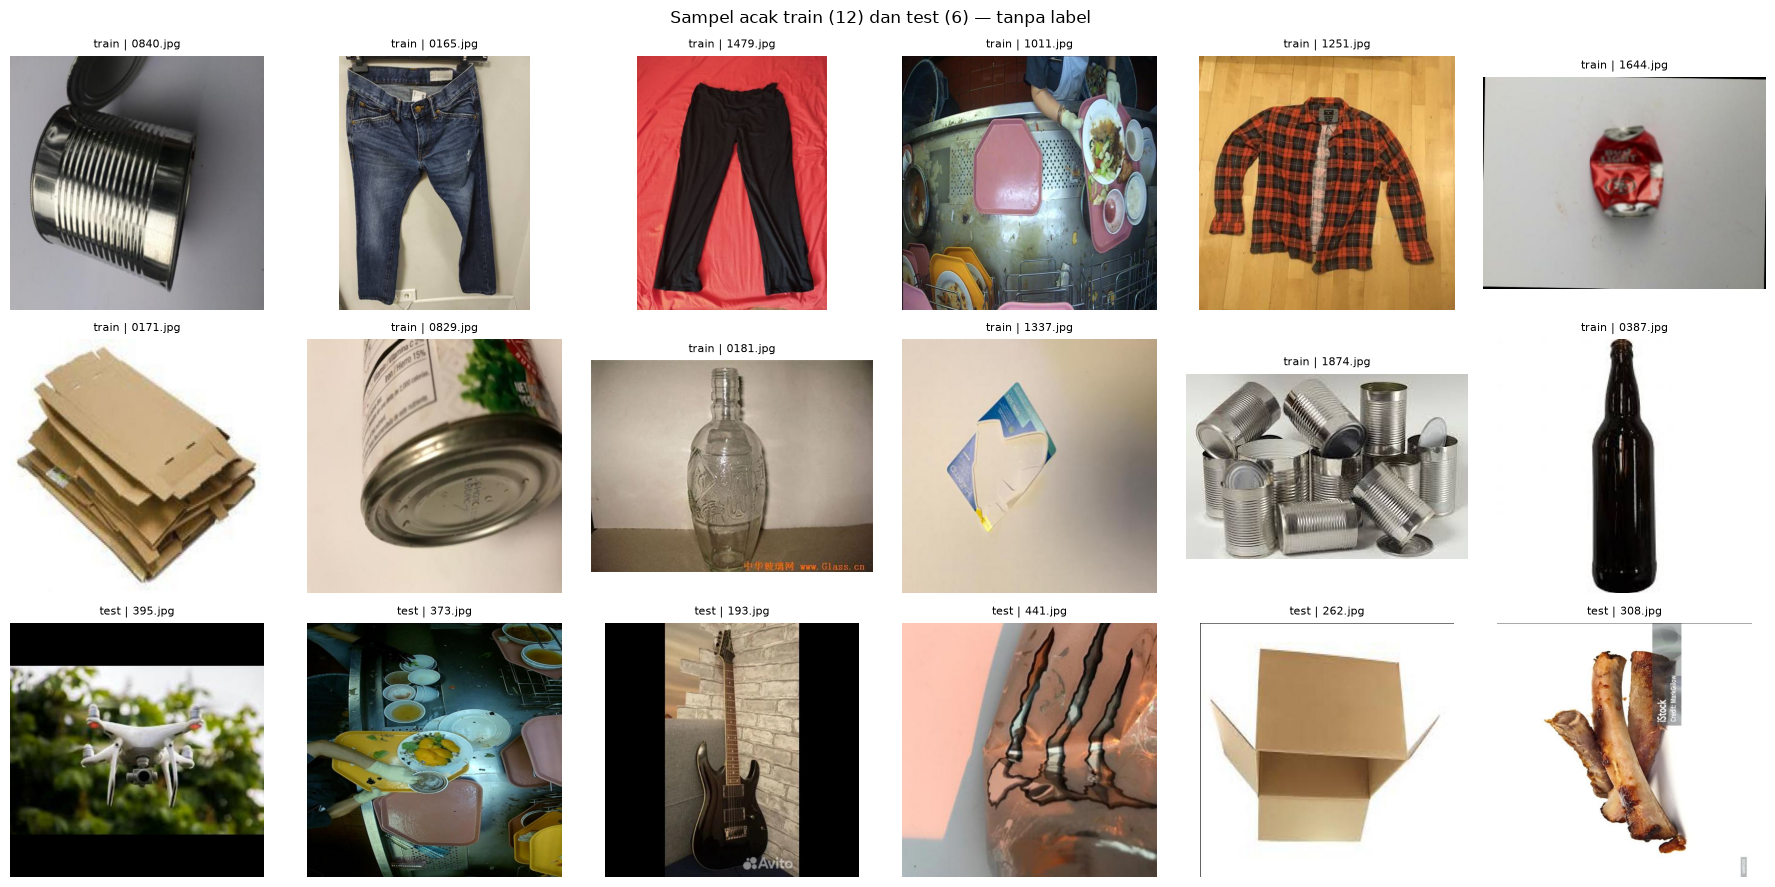

In [6]:
# ----------------------------
# 1.5 Visual EDA ringkas
# ----------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, col in zip(axes[:2], ["width", "height"]):
    for split in ["train", "test"]:
        vals = manifest.loc[manifest.split == split, col].dropna()
        ax.hist(vals, bins=36, alpha=0.55, label=split)
    ax.set_title(f"Sebaran {col} (piksel)")
    ax.set_xlabel(col); ax.set_ylabel("jumlah")
    ax.legend()
for split in ["train", "test"]:
    d = manifest[manifest.split == split]
    axes[2].hist((d.width / d.height).dropna(), bins=36, alpha=0.55, label=split)
axes[2].set_title("Sebaran rasio aspek (w/h)")
axes[2].set_xlabel("w/h"); axes[2].legend()
plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
picks_train = rng.choice(train_df.path.values, size=12, replace=False)
picks_test = rng.choice(test_df.path.values, size=6, replace=False)
picks = [("train", p) for p in picks_train] + [("test", p) for p in picks_test]

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for ax, (split, p) in zip(axes.ravel(), picks):
    ax.imshow(load_image(p))
    ax.set_title(f"{split} | {Path(p).name}", fontsize=8)
    ax.axis("off")
fig.suptitle("Sampel acak train (12) dan test (6) — tanpa label", fontsize=12)
plt.tight_layout(); plt.show()

### 1.6 Insight: warna, cahaya, dan domain shift

Ukuran gambar sudah diperiksa, tetapi ukuran saja tidak menangkap perbedaan pencahayaan atau saturasi. Sel ini menghitung statistik warna ringan pada resize 64×64: brightness, contrast, saturation, dan warmth (R−B). Tujuannya bukan menilai kualitas foto, melainkan memeriksa apakah train dan test punya distribusi visual yang cukup mirip.

**Yang dicari:** selisih mean yang kecil dan KS statistic yang rendah. Jika selisihnya besar, preprocessing atau augmentasi menjadi lebih penting; jika kecil, resize + center-crop masih masuk akal.

Statistik warna dimuat: artifacts_nb/eda_color_stats_v1.csv


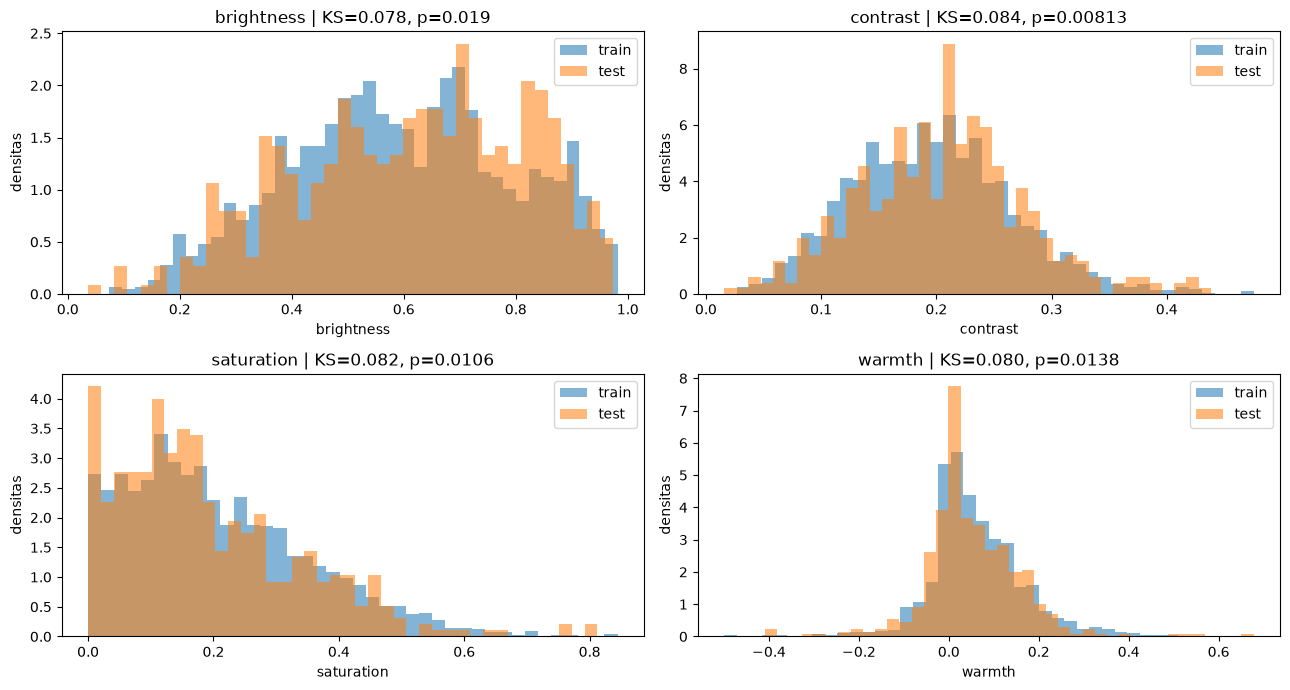

      brightness         contrast         saturation          warmth        
            mean     std     mean     std       mean     std    mean     std
split                                                                       
test      0.6124  0.2016   0.2052  0.0715     0.1904  0.1456  0.0501  0.1107
train     0.5939  0.1969   0.1961  0.0699     0.2088  0.1458  0.0608  0.1067
Batas tafsir: KS mengukur perbedaan distribusi, bukan kualitas gambar. Selisih kecil tetap bisa berarti domain shift halus.


In [7]:
# ----------------------------
# 1.6 Statistik warna ringan (cache; resize 64x64)
# ----------------------------
color_path = ART_DIR / "eda_color_stats_v1.csv"
if color_path.exists():
    color_stats = pd.read_csv(color_path)
    print(f"Statistik warna dimuat: {color_path.relative_to(ROOT)}")
else:
    rows = []
    t0 = time.time()
    for split, df_split in [("train", manifest[manifest.split == "train"]),
                            ("test", manifest[manifest.split == "test"])]:
        for _, r in df_split.iterrows():
            with Image.open(ROOT / r.path) as im:
                im = ImageOps.exif_transpose(im).convert("RGB").resize((64, 64))
                arr = np.asarray(im, dtype=np.float32) / 255.0
                hsv = np.asarray(im.convert("HSV"), dtype=np.float32) / 255.0
            gray = arr.mean(axis=2)
            rows.append({
                "split": split,
                "brightness": float(gray.mean()),
                "contrast": float(gray.std()),
                "saturation": float(hsv[:, :, 1].mean()),
                "warmth": float(arr[:, :, 0].mean() - arr[:, :, 2].mean()),
            })
    color_stats = pd.DataFrame(rows)
    color_stats.to_csv(color_path, index=False)
    print(f"Statistik warna dihitung ({time.time()-t0:.1f}s): {color_path.relative_to(ROOT)}")

from scipy.stats import ks_2samp

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, col in zip(axes.ravel(), ["brightness", "contrast", "saturation", "warmth"]):
    for split in ["train", "test"]:
        vals = color_stats.loc[color_stats.split == split, col]
        ax.hist(vals, bins=40, alpha=0.55, density=True, label=split)
    ks = ks_2samp(color_stats.loc[color_stats.split == "train", col],
                  color_stats.loc[color_stats.split == "test", col])
    ax.set_title(f"{col} | KS={ks.statistic:.3f}, p={ks.pvalue:.3g}")
    ax.set_xlabel(col); ax.set_ylabel("densitas"); ax.legend()
plt.tight_layout(); plt.show()

summary_color = color_stats.groupby("split")[["brightness", "contrast", "saturation", "warmth"]].agg(["mean", "std"]).round(4)
print(summary_color.to_string())
print("Batas tafsir: KS mengukur perbedaan distribusi, bukan kualitas gambar. Selisih kecil tetap bisa berarti domain shift halus.")

**Insight.** Distribusi warna train dan test tidak identik, tetapi selisihnya kecil: test sedikit lebih terang dan sedikit kurang saturasi. KS statistic berada di kisaran 0,08 untuk keempat kanal, jadi tidak ada bukti domain shift besar. Karena itu notebook tetap memakai resize + center-crop dan TTA flip, tanpa domain adaptation yang rumit. Risikonya tetap dicatat: gambar test yang lebih terang atau berwarna pudar bisa lebih sering masuk kelas minoritas.

## Bab 2 — Ekstraksi Fitur 

**Tujuan:** memuat/menghitung fitur DINOv2 dan ConvNeXt dengan TTA flip, lalu memastikan cache valid.

In [8]:
# ----------------------------
# 2.1 Definisi model & loader cache
# ----------------------------
MODELS = {
    "dinov2": {
        "model_name": "vit_large_patch14_reg4_dinov2.lvd142m",
        "img_size": 448,
        "dim": 1024,
        "pretraining": "DINOv2 self-supervised, image-only (LVD-142M)",
    },
    "convnext": {
        "model_name": "convnext_large.fb_in22k_ft_in1k_384",
        "img_size": None,
        "dim": 1536,
        "pretraining": "Supervised ImageNet-22k -> ImageNet-1k (vision-only)",
    },
}

FORBIDDEN_TOKENS = ("clip", "siglip", "eva-clip", "open_clip", "llava", "blip", "florence", "paligemma")
bad_models = [m["model_name"] for m in MODELS.values()
              if any(t in m["model_name"].lower() for t in FORBIDDEN_TOKENS)]
require(not bad_models, f"Model terlarang terdeteksi: {bad_models}. Ganti dengan backbone vision-only.")

def build_transform(model, img_size=None):
    """Transform inference dari config timm; img_size menimpa resolusi input."""
    cfg = timm.data.resolve_data_config({}, model=model)
    if img_size is not None:
        cfg = dict(cfg)
        cfg["input_size"] = (3, int(img_size), int(img_size))
        cfg["crop_pct"] = 1.0
    return timm.data.create_transform(**cfg, is_training=False)

@torch.inference_mode()
def embed_paths(model, transform, paths, batch_size):
    """Embedding TTA flip: f(x) + f(flip(x)), lalu L2-normalize. OOM -> batch diturunkan."""
    out, i, bs = [], 0, int(batch_size)
    t0 = time.time()
    while i < len(paths):
        chunk = paths[i:i + bs]
        x = torch.stack([transform(load_image(p)) for p in chunk]).to(DEVICE)
        try:
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
                f = model(x) + model(torch.flip(x, dims=[3]))
            out.append(F.normalize(f.float(), dim=-1).cpu().numpy())
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and bs > 1:
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
                bs = max(1, bs // 2)
                print(f"  OOM: batch diturunkan menjadi {bs}, ulangi batch yang sama...")
                continue
            raise
        i += len(chunk)
        if i % max(bs * 10, 10) == 0 or i == len(paths):
            print(f"  {i}/{len(paths)} gambar | {time.time()-t0:.0f}s")
    return np.concatenate(out, axis=0)

def load_or_extract(name, spec):
    """Muat cache fitur; jika tidak ada, ekstrak hanya ketika RUN_EXTRACT=True."""
    cache = ART_DIR / f"features_{name}.npz"
    source = "cache"
    if not cache.exists():
        require(RUN_EXTRACT,
                f"Cache {cache.name} tidak ada. Set RUN_EXTRACT=True di Bab 0, lalu jalankan ulang Bab 2. "
                "Jangan biarkan bab berikutnya memakai fitur kosong.")
        print(f"[ekstraksi] {name}: {spec['model_name']} ...")
        extra = {"img_size": spec["img_size"]} if spec["img_size"] else {}
        model = timm.create_model(spec["model_name"], pretrained=True, num_classes=0, **extra).to(DEVICE).eval()
        transform = build_transform(model, spec["img_size"])
        tr = embed_paths(model, transform, train_df.path.tolist(), BATCH_SIZE)
        te = embed_paths(model, transform, test_df.path.tolist(), BATCH_SIZE)
        np.savez(cache, train=tr, test=te)
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        source = "extracted"
        print(f"[ekstraksi] selesai -> {cache.relative_to(ROOT)}")

    with np.load(cache) as z:
        tr = np.asarray(z["train"], dtype=np.float32)
        te = np.asarray(z["test"], dtype=np.float32)

    require(tr.shape == (len(train_df), spec["dim"]),
            f"{name}: shape train {tr.shape}, seharusnya {(len(train_df), spec['dim'])}. Cache tidak cocok; hapus/rename cache lalu RUN_EXTRACT=True.")
    require(te.shape == (len(test_df), spec["dim"]),
            f"{name}: shape test {te.shape}, seharusnya {(len(test_df), spec['dim'])}. Cache tidak cocok.")
    require(np.isfinite(tr).all() and np.isfinite(te).all(), f"{name}: ada NaN/Inf di fitur.")
    n_tr = np.linalg.norm(tr, axis=1)
    n_te = np.linalg.norm(te, axis=1)
    require(np.abs(n_tr - 1).max() < 1e-3 and np.abs(n_te - 1).max() < 1e-3,
            f"{name}: fitur belum L2-normalized (norm min/max train {n_tr.min():.4f}/{n_tr.max():.4f}).")
    return tr, te, source

features = {}
for name, spec in MODELS.items():
    tr, te, src = load_or_extract(name, spec)
    features[name] = {"train": tr, "test": te, "source": src, "spec": spec}
    print(f"{name:9s} | train {tr.shape} | test {te.shape} | sumber: {src} | "
          f"norm {np.linalg.norm(tr, axis=1).mean():.4f} | NaN {np.isnan(tr).sum()}")

dinov2    | train (1920, 1024) | test (480, 1024) | sumber: cache | norm 1.0000 | NaN 0
convnext  | train (1920, 1536) | test (480, 1536) | sumber: cache | norm 1.0000 | NaN 0


In [9]:
# ----------------------------
# 2.2 Fitur gabungan, metadata, dan Gate 2
# ----------------------------
parts_tr = [features[n]["train"] for n in MODELS]
parts_te = [features[n]["test"] for n in MODELS]
X_train_comb = np.hstack(parts_tr) / np.sqrt(len(MODELS))
X_test_comb = np.hstack(parts_te) / np.sqrt(len(MODELS))

# Setelah pembagian sqrt(n), norma vektor gabungan ~1.
require(abs(np.linalg.norm(X_train_comb, axis=1).mean() - 1) < 1e-3,
        "Fitur gabungan train tidak ternormalisasi dengan benar.")
require(abs(np.linalg.norm(X_test_comb, axis=1).mean() - 1) < 1e-3,
        "Fitur gabungan test tidak ternormalisasi dengan benar.")

meta_core = {
    "models": {n: {"model_name": s["model_name"], "img_size": s["img_size"], "dim": s["dim"],
                   "pretraining": s["pretraining"], "source": features[n]["source"]}
               for n, s in MODELS.items()},
    "tta": "original + horizontal flip, dijumlahkan, lalu L2-normalize",
    "combined": "hstack(dinov2, convnext) / sqrt(2)",
    "n_train": len(train_df), "n_test": len(test_df),
    "dims": {n: MODELS[n]["dim"] for n in MODELS},
    "combined_dim": int(X_train_comb.shape[1]),
    "forbidden_tokens_checked": list(FORBIDDEN_TOKENS),
}
meta_path = ART_DIR / "features_meta.json"
meta_core_json = json.dumps(meta_core, sort_keys=True)
if meta_path.exists():
    try:
        old = json.loads(meta_path.read_text(encoding="utf-8"))
        old_core = json.dumps({k: v for k, v in old.items() if k != "written_at"}, sort_keys=True)
    except Exception:
        old_core = None
    if old_core != meta_core_json:
        meta_path = ART_DIR / f"features_meta_{hashlib.md5(meta_core_json.encode()).hexdigest()[:8]}.json"
save_json({"written_at": RUN_TS, **meta_core}, meta_path)

gate2 = all(np.isfinite(features[n]["train"]).all() and np.isfinite(features[n]["test"]).all() for n in MODELS)
print("RINGKASAN BAB 2")
for n in MODELS:
    print(f"- {n:9s}: {features[n]['train'].shape[1]}-d | train {features[n]['train'].shape[0]} | "
          f"test {features[n]['test'].shape[0]} | cache={features[n]['source']}")
print(f"- Fitur gabungan: {X_train_comb.shape} (train), {X_test_comb.shape} (test).")
print(f"- Metadata: {meta_path.relative_to(ROOT)}")
print(f"- Gate 2: {'LULUS' if gate2 else 'GAGAL'} - tidak ada NaN/Inf dan dimensi sesuai.")
print("Risiko: fitur TTA sudah dinormalisasi; jangan menambahkan scaler yang mengubah arah vektor. "
      "Jika RUN_EXTRACT=True di mesin tanpa internet, unduh bobot timm terlebih dahulu.")

RINGKASAN BAB 2
- dinov2   : 1024-d | train 1920 | test 480 | cache=cache
- convnext : 1536-d | train 1920 | test 480 | cache=cache
- Fitur gabungan: (1920, 2560) (train), (480, 2560) (test).
- Metadata: artifacts_nb/features_meta_6e84b58d.json
- Gate 2: LULUS - tidak ada NaN/Inf dan dimensi sesuai.
Risiko: fitur TTA sudah dinormalisasi; jangan menambahkan scaler yang mengubah arah vektor. Jika RUN_EXTRACT=True di mesin tanpa internet, unduh bobot timm terlebih dahulu.


### 2.3 Geometri ruang fitur

Sebelum clustering, penting diketahui seberapa padat ruang fitur. Jika banyak gambar punya tetangga dengan cosine sangat tinggi, validasi group-aware menjadi wajib. Jika PCA hanya menjelaskan sedikit variansi dalam beberapa komponen, struktur kelas memang tidak linear.

**Yang dicari:** kurva variansi kumulatif dan sebaran cosine ke tetangga terdekat. Ambang near-duplicate 0,95 dipakai untuk membentuk grup duplikat di Bab 3.

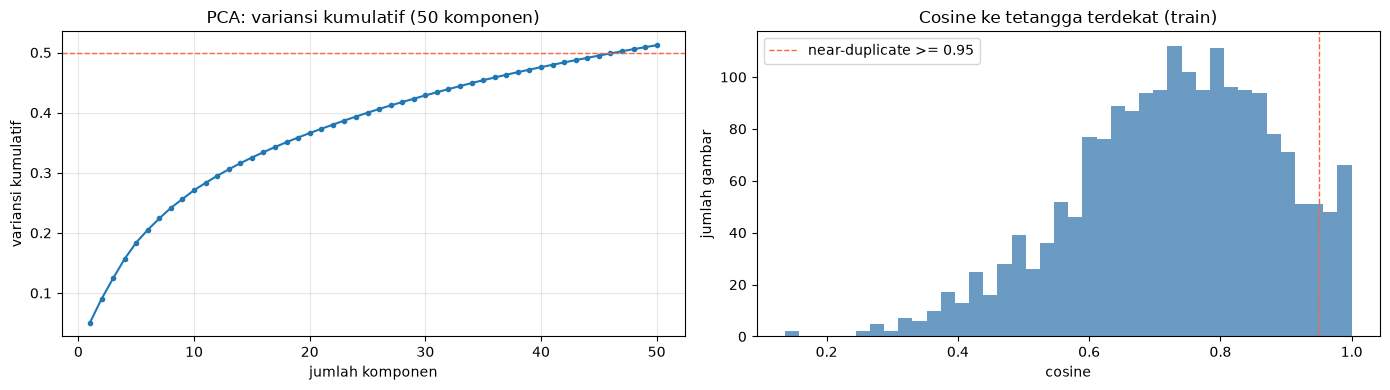

PCA 10/20/50 komponen: 0.271 / 0.366 / 0.512
Cosine tetangga terdekat: median=0.740 | p10=0.521 | p90=0.924
Gambar dengan tetangga cosine >= 0.95: 138
Implikasi: ruang fitur padat; evaluasi harus group-aware dan klaster bisa memiliki batas tipis.


In [10]:
# ----------------------------
# 2.3 Geometri fitur: PCA dan jarak tetangga terdekat
# ----------------------------
pca_probe = PCA(n_components=50, random_state=SEED).fit(X_train_comb)
cum_var = np.cumsum(pca_probe.explained_variance_ratio_)
nn_probe = NearestNeighbors(n_neighbors=2, metric="cosine").fit(X_train_comb)
dist_probe, _ = nn_probe.kneighbors(X_train_comb)
cos_nn = 1.0 - dist_probe[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(np.arange(1, len(cum_var) + 1), cum_var, marker="o", markersize=3)
axes[0].axhline(0.5, color="tomato", linestyle="--", linewidth=1)
axes[0].set_title("PCA: variansi kumulatif (50 komponen)")
axes[0].set_xlabel("jumlah komponen"); axes[0].set_ylabel("variansi kumulatif")
axes[0].grid(alpha=0.3)
axes[1].hist(cos_nn, bins=40, color="steelblue", alpha=0.8)
axes[1].axvline(NEAR_DUP_COS, color="tomato", linestyle="--", linewidth=1,
                label=f"near-duplicate >= {NEAR_DUP_COS}")
axes[1].set_title("Cosine ke tetangga terdekat (train)")
axes[1].set_xlabel("cosine"); axes[1].set_ylabel("jumlah gambar"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"PCA 10/20/50 komponen: {cum_var[9]:.3f} / {cum_var[19]:.3f} / {cum_var[49]:.3f}")
print(f"Cosine tetangga terdekat: median={np.median(cos_nn):.3f} | "
      f"p10={np.quantile(cos_nn, 0.10):.3f} | p90={np.quantile(cos_nn, 0.90):.3f}")
print(f"Gambar dengan tetangga cosine >= {NEAR_DUP_COS}: {int((cos_nn >= NEAR_DUP_COS).sum())}")
print("Implikasi: ruang fitur padat; evaluasi harus group-aware dan klaster bisa memiliki batas tipis.")

## Bab 3 — Fold Beku dengan Grup Duplikat

**Tujuan:** membekukan skema validasi yang tidak membocorkan gambar kembar antar fold.

In [11]:
# ----------------------------
# 3.1 Bangun grup duplikat (piksel + near-duplicate DINOv2)
# ----------------------------
class DSU:
    def __init__(self, n):
        self.p = list(range(n))
    def find(self, x):
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra

n_train = len(train_df)
pos = {f: i for i, f in enumerate(train_df.filename)}
dsu = DSU(n_train)

# (a) Duplikat piksel: semua file dengan hash sama -> satu grup.
tr_manifest = manifest[manifest.split == "train"]
for h, sub in tr_manifest.groupby("pixel_hash"):
    ids = [pos[f] for f in sub.filename if f in pos]
    for j in ids[1:]:
        dsu.union(ids[0], j)

# (b) Near-duplicate DINOv2: cosine >= 0.95 -> single-linkage.
near_labels = AgglomerativeClustering(
    n_clusters=None, metric="cosine", linkage="single",
    distance_threshold=1.0 - NEAR_DUP_COS,
).fit_predict(features["dinov2"]["train"])
for g in np.unique(near_labels):
    ids = np.where(near_labels == g)[0]
    for j in ids[1:]:
        dsu.union(int(ids[0]), int(j))

roots = [dsu.find(i) for i in range(n_train)]
uniq = {r: i for i, r in enumerate(sorted(set(roots)))}
groups = np.array([uniq[r] for r in roots], dtype=int)

groups_path = ART_DIR / "dup_groups.csv"
if groups_path.exists():
    old_groups = pd.read_csv(groups_path)
    if old_groups.filename.tolist() == train_df.filename.tolist() and "group" in old_groups:
        groups = old_groups.group.to_numpy()
        print(f"Grup duplikat dimuat dari cache: {groups_path.relative_to(ROOT)}")
    else:
        groups_path = next_version_path(ART_DIR, "dup_groups")
        print(f"Cache grup tidak cocok; menulis versi baru {groups_path.name}.")
        pd.DataFrame({"filename": train_df.filename, "group": groups}).to_csv(groups_path, index=False)
else:
    pd.DataFrame({"filename": train_df.filename, "group": groups}).to_csv(groups_path, index=False)
    print(f"Grup duplikat dibuat: {groups_path.relative_to(ROOT)}")

group_sizes = pd.Series(groups).value_counts()
n_groups = int(groups.max()) + 1
print(f"Grup: {n_groups} | grup >1 gambar: {int((group_sizes > 1).sum())} | "
      f"gambar di grup >1: {int(group_sizes[group_sizes > 1].sum())} | ukuran maks: {int(group_sizes.max())}")
print(f"Near-duplicate DINOv2: {(near_labels >= 0).sum()} gambar, {len(np.unique(near_labels))} komponen.")

Grup duplikat dimuat dari cache: artifacts_nb/dup_groups.csv
Grup: 1807 | grup >1 gambar: 86 | gambar di grup >1: 199 | ukuran maks: 10
Near-duplicate DINOv2: 1920 gambar, 1807 komponen.


In [12]:
# ----------------------------
# 3.2 Buat / muat fold beku
# ----------------------------
fold_cols = [f"fold_s{s}" for s in CV_SEEDS]
folds_path = ART_DIR / "folds.csv"

if folds_path.exists():
    folds = pd.read_csv(folds_path)
    print(f"Fold dimuat dari cache (DIBEKUKAN): {folds_path.relative_to(ROOT)}")
    require(set(fold_cols).issubset(folds.columns),
            f"folds.csv tidak punya kolom {fold_cols}. Jangan hapus/ubah file fold yang sudah beku.")
else:
    require(n_train == 1920, "Fold hanya dibuat untuk 1.920 gambar train.")
    # Proxy stratifikasi tanpa label: KMeans(8) pada fitur gabungan.
    proxy = KMeans(n_clusters=8, n_init=20, random_state=SEED).fit_predict(X_train_comb)
    folds = pd.DataFrame({"filename": train_df.filename, "group": groups, "proxy_class": proxy})
    for s in CV_SEEDS:
        sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=s)
        assignment = np.full(n_train, -1, dtype=int)
        for k, (_, va) in enumerate(sgkf.split(X_train_comb, proxy, groups)):
            assignment[va] = k
        require((assignment >= 0).all(), f"Seed {s}: ada gambar tanpa fold.")
        folds[f"fold_s{s}"] = assignment
    folds.to_csv(folds_path, index=False)
    save_json({
        "created_at": RUN_TS, "seed": SEED, "cv_seeds": CV_SEEDS, "n_splits": N_SPLITS,
        "near_dup_cos": NEAR_DUP_COS, "grouping": "pixel hash + DINOv2 cosine>=threshold (single-linkage)",
        "strata_proxy": "KMeans(8) on combined features, no labels used",
        "n_groups": int(n_groups), "sha256": sha256_file(folds_path),
    }, ART_DIR / "fold_manifest.json")
    print(f"Fold dibuat sekali dan dibekukan: {folds_path.relative_to(ROOT)}")

# Selaraskan urutan dengan train_df tanpa mengubah isi fold.
folds = train_df[["filename"]].merge(folds, on="filename", how="left", validate="one_to_one")
require(len(folds) == n_train, "Jumlah baris fold tidak sama dengan jumlah train.")
require(folds[fold_cols].notna().all().all(), "Ada gambar tanpa nilai fold.")
for c in fold_cols:
    folds[c] = folds[c].astype(int)

# Validasi integritas grup dan ukuran fold.
for c in fold_cols:
    g = folds.groupby("group")[c].nunique()
    require((g == 1).all(), f"{c}: ada grup duplikat yang terpecah antar fold.")
    counts = folds[c].value_counts().sort_index()
    require(len(counts) == N_SPLITS, f"{c}: jumlah fold {len(counts)}, seharusnya {N_SPLITS}.")
    require(counts.between(330, 440).all(), f"{c}: ukuran fold tidak wajar: {counts.to_dict()}")

fold_table = pd.DataFrame({f"seed {s}": folds[f"fold_s{s}"].value_counts().sort_index() for s in CV_SEEDS})
print("\nUkuran fold validasi per seed:")
print(fold_table.to_string())
print(f"\nJumlah grup: {folds.group.nunique()} | ukuran grup maks: {folds.group.value_counts().max()}")

# Cek keseimbangan proxy (bukan label).
proxy_cols = ["proxy_class"] if "proxy_class" in folds.columns else []
if proxy_cols:
    glob = folds.proxy_class.value_counts(normalize=True).sort_index()
    for s in CV_SEEDS:
        c = f"fold_s{s}"
        max_dev = max(
            float((folds.loc[folds[c] == k, "proxy_class"].value_counts(normalize=True).reindex(glob.index).fillna(0) - glob).abs().max())
            for k in range(N_SPLITS)
        )
        print(f"Seed {s}: deviasi maks proporsi proxy antar fold = {max_dev:.3f}")

gate3 = all(len(folds[f"fold_s{s}"].value_counts()) == N_SPLITS for s in CV_SEEDS)
print(f"\nGate 3 (fold): {'LULUS' if gate3 else 'GAGAL'}")
require(gate3, "Gate 3 gagal: skema fold tidak lengkap.")

Fold dimuat dari cache (DIBEKUKAN): artifacts_nb/folds.csv

Ukuran fold validasi per seed:
   seed 0  seed 1  seed 2
0     384     384     384
1     384     384     384
2     384     384     384
3     384     384     384
4     384     384     384

Jumlah grup: 1807 | ukuran grup maks: 10
Seed 0: deviasi maks proporsi proxy antar fold = 0.002
Seed 1: deviasi maks proporsi proxy antar fold = 0.002
Seed 2: deviasi maks proporsi proxy antar fold = 0.002

Gate 3 (fold): LULUS


### 3.3 Visual: grup duplikat dan ukuran fold

Tabel fold sudah memastikan tidak ada grup yang terpecah. Visual ini menunjukkan dua hal yang lebih mudah dibaca: seberapa besar grup duplikat, dan apakah ukuran fold seimbang di ketiga seed.

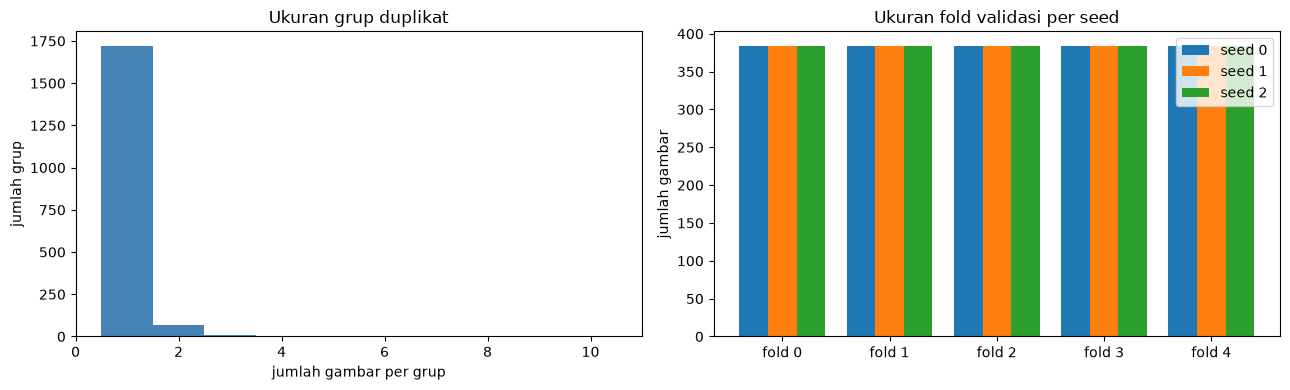

Grup duplikat: 86 dari 1807 berisi >1 gambar; ukuran maks 10.
Ukuran fold min/maks: 384/384 gambar.
Batas tafsir: ukuran fold seimbang mencegah satu kelas dominan di satu fold, tetapi tidak membuktikan label benar.


In [13]:
# ----------------------------
# 3.3 Visual: grup duplikat dan ukuran fold
# ----------------------------
group_sizes_all = folds.groupby("group").size()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bins = np.arange(1, int(group_sizes_all.max()) + 2)
axes[0].hist(group_sizes_all, bins=bins, align="left", color="steelblue")
axes[0].set_title("Ukuran grup duplikat")
axes[0].set_xlabel("jumlah gambar per grup"); axes[0].set_ylabel("jumlah grup")
width = 0.8 / len(CV_SEEDS)
xs = np.arange(N_SPLITS)
for i, s in enumerate(CV_SEEDS):
    counts = folds[f"fold_s{s}"].value_counts().sort_index().reindex(range(N_SPLITS), fill_value=0)
    axes[1].bar(xs + i * width, counts.values, width, label=f"seed {s}")
axes[1].set_xticks(xs + width * (len(CV_SEEDS) - 1) / 2)
axes[1].set_xticklabels([f"fold {k}" for k in range(N_SPLITS)])
axes[1].set_title("Ukuran fold validasi per seed")
axes[1].set_ylabel("jumlah gambar"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Grup duplikat: {(group_sizes_all > 1).sum()} dari {len(group_sizes_all)} berisi >1 gambar; "
      f"ukuran maks {int(group_sizes_all.max())}.")
print(f"Ukuran fold min/maks: {int(fold_table.min().min())}/{int(fold_table.max().max())} gambar.")
print("Batas tafsir: ukuran fold seimbang mencegah satu kelas dominan di satu fold, tetapi tidak membuktikan label benar.")

## Bab 4 — Clustering k=64

**Tujuan:** membangun klaster k=64 dari fitur dan mengukur sensitivitas k=32/64/128 sebagai bukti stabilitas, bukan untuk auto-select.

In [14]:
# ============================================================
# BAB 4 - CLUSTERING k=64 (FILE BARU, TIDAK MEMBACA clusters.csv LAMA)
# ============================================================
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

require(N_CLUSTERS == 64, "Bab 4 revisi ini mengunci k=64. Jika ingin k lain, buat keputusan baru dan ubah CLUSTER_VERSION.")

def macro_purity(labels, macro):
    # Rata-rata fraksi mayoritas proxy_class di dalam setiap klaster.
    s = pd.DataFrame({"c": labels, "m": macro})
    return float(s.groupby("c").m.agg(lambda x: x.value_counts(normalize=True).iloc[0]).mean())

def knn_indices(X, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="cosine").fit(X)
    _, idx = nn.kneighbors(X)
    return idx[:, 1:]

def pairwise_ari_nmi(label_list):
    aris, nmis = [], []
    for i in range(len(label_list)):
        for j in range(i + 1, len(label_list)):
            aris.append(adjusted_rand_score(label_list[i], label_list[j]))
            nmis.append(normalized_mutual_info_score(label_list[i], label_list[j]))
    return np.array(aris, dtype=float), np.array(nmis, dtype=float)


print(f"N_CLUSTERS={N_CLUSTERS} | K_GRID={K_GRID} | KMeans seeds={N_KMEANS_SEEDS}")

N_CLUSTERS=64 | K_GRID=[32, 64, 128] | KMeans seeds=[42, 43, 44]


In [15]:
# ----------------------------
# 4.1 Sensitivitas k: ARI/NMI antar seed KMeans + purity proxy
# ----------------------------
sens_path = ART_DIR / f"k_sensitivity_{CLUSTER_VERSION}.csv"
sens_detail_path = ART_DIR / f"k_sensitivity_detail_{CLUSTER_VERSION}.csv"
sens_labels_path = ART_DIR / f"k_sensitivity_labels_{CLUSTER_VERSION}.npz"

if sens_path.exists() and sens_detail_path.exists() and sens_labels_path.exists() and not RUN_CLUSTER:
    sens = pd.read_csv(sens_path)
    sens_detail = pd.read_csv(sens_detail_path)
    with np.load(sens_labels_path) as z:
        sens_labels = {k: np.asarray(z[k], dtype=int) for k in z.files}
    print(f"Tabel sensitivitas dimuat: {sens_path.relative_to(ROOT)}")
elif sens_path.exists() and RUN_CLUSTER:
    sens = pd.read_csv(sens_path)
    sens_detail = pd.read_csv(sens_detail_path)
    with np.load(sens_labels_path) as z:
        sens_labels = {k: np.asarray(z[k], dtype=int) for k in z.files}
    print("RUN_CLUSTER=True, tetapi file versi ini sudah ada. Tidak menimpa; naikkan CLUSTER_VERSION untuk hitung ulang.")
else:
    print(f"Menghitung sensitivitas k={K_GRID} x {len(N_KMEANS_SEEDS)} seed KMeans ...")
    t0 = time.time()
    rows = []
    sens_labels = {}
    for k in K_GRID:
        for rs in N_KMEANS_SEEDS:
            km = KMeans(n_clusters=k, n_init=3, random_state=rs).fit(X_train_comb)
            lab = km.labels_
            sens_labels[f"k{k}_s{rs}"] = lab.astype(int)
            sizes_k = np.bincount(lab, minlength=k)
            rows.append({
                "k": int(k),
                "kmeans_seed": int(rs),
                "purity_proxy": macro_purity(lab, folds.proxy_class.to_numpy()),
                "min_size": int(sizes_k.min()),
                "median_size": float(np.median(sizes_k)),
                "max_size": int(sizes_k.max()),
                "n_singletons": int((sizes_k == 1).sum()),
                "inertia": float(km.inertia_),
            })
            print(f"  k={k} seed={rs}: selesai ({time.time()-t0:.0f}s)")

    sens_detail = pd.DataFrame(rows)
    summary = []
    for k, g in sens_detail.groupby("k", sort=True):
        labs = [sens_labels[f"k{k}_s{rs}"] for rs in N_KMEANS_SEEDS]
        aris, nmis = pairwise_ari_nmi(labs)
        summary.append({
            "k": int(k),
            "n_seeds": len(N_KMEANS_SEEDS),
            "ari_mean": float(aris.mean()) if len(aris) else np.nan,
            "ari_min": float(aris.min()) if len(aris) else np.nan,
            "nmi_mean": float(nmis.mean()) if len(nmis) else np.nan,
            "purity_mean": float(g.purity_proxy.mean()),
            "purity_min": float(g.purity_proxy.min()),
            "min_size": int(g.min_size.min()),
            "median_size": float(g.median_size.mean()),
            "max_size": int(g.max_size.max()),
            "n_singletons": int(g.n_singletons.max()),
        })
    sens = pd.DataFrame(summary).sort_values("k").reset_index(drop=True)
    sens_detail.to_csv(sens_detail_path, index=False)
    sens.to_csv(sens_path, index=False)
    np.savez_compressed(sens_labels_path, **sens_labels)
    print(f"Selesai dalam {time.time()-t0:.1f} detik: {sens_path.relative_to(ROOT)}")

print("\nSensitivitas k (ARI/NMI antar seed KMeans; purity proxy bukan akurasi):")
print(sens[["k", "ari_mean", "ari_min", "nmi_mean", "purity_mean", "purity_min",
            "min_size", "median_size", "max_size", "n_singletons"]].round(3).to_string(index=False))

RUN_CLUSTER=True, tetapi file versi ini sudah ada. Tidak menimpa; naikkan CLUSTER_VERSION untuk hitung ulang.

Sensitivitas k (ARI/NMI antar seed KMeans; purity proxy bukan akurasi):
  k  ari_mean  ari_min  nmi_mean  purity_mean  purity_min  min_size  median_size  max_size  n_singletons
 32     0.669    0.637     0.853        0.929       0.922         8       55.000       164             0
 64     0.604    0.596     0.851        0.919       0.912         3       27.500        88             0
128     0.605    0.592     0.867        0.923       0.911         2       12.833        59             0


In [16]:
# ----------------------------
# 4.2 Klaster final k=64 
# ----------------------------
cluster_path = LABEL_DIR / f"clusters_k64_{CLUSTER_VERSION}.csv"

if cluster_path.exists():
    clusters = pd.read_csv(cluster_path)
    require({"filename", "cluster"}.issubset(clusters.columns),
            f"{cluster_path.name} harus punya kolom filename dan cluster.")
    cluster_source = "frozen"
    print(f"Klaster dimuat (DIBEKUKAN): {cluster_path.relative_to(ROOT)}")
else:
    print(f"Membangun klaster k={N_CLUSTERS} (n_init=10, seed={SEED}) ...")
    t0 = time.time()
    km_final = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit(X_train_comb)
    lab_final = km_final.labels_.astype(int)
    dist_final = km_final.transform(X_train_comb).min(axis=1)
    clusters = pd.DataFrame({
        "filename": train_df.filename,
        "cluster": lab_final,
        "dist_to_center": np.round(dist_final, 4),
        "k": N_CLUSTERS,
        "kmeans_seed": SEED,
        "version": CLUSTER_VERSION,
        "created_at": RUN_TS,
    })
    clusters.to_csv(cluster_path, index=False)
    cluster_source = "created"
    print(f"Klaster dibuat dan dibekukan: {cluster_path.relative_to(ROOT)} ({time.time()-t0:.1f}s)")

# Selaraskan urutan dengan train_df tanpa mengubah isi.
clusters = train_df[["filename"]].merge(clusters, on="filename", how="left", validate="one_to_one")
require(len(clusters) == len(train_df), "Jumlah baris klaster tidak sama dengan jumlah train.")
require(clusters.cluster.notna().all(), "Ada gambar train tanpa klaster. Perbaiki file klaster.")
clusters["cluster"] = clusters.cluster.astype(int)
require(clusters.filename.tolist() == train_df.filename.tolist(), "Urutan filename klaster tidak sama dengan train.")
require(clusters.cluster.nunique() == N_CLUSTERS,
        f"Klaster final punya {clusters.cluster.nunique()} klaster, seharusnya {N_CLUSTERS}.")
require(set(clusters.cluster.unique()) == set(range(N_CLUSTERS)),
        "ID klaster tidak lengkap 0..63. Jangan lanjut.")
sizes = clusters.cluster.value_counts().sort_index()
require(int(sizes.min()) >= 3, f"Ada klaster <3 gambar (min={int(sizes.min())}). Naikkan k atau periksa fitur.")

# Centroid untuk assignment test dan sanity check duplikat.
centroids = np.vstack([X_train_comb[clusters.cluster.to_numpy() == c].mean(axis=0) for c in range(N_CLUSTERS)])
centroids = normalize(centroids)
np.savez_compressed(ART_DIR / f"cluster_centroids_{CLUSTER_VERSION}.npz",
                    centroids=centroids, cluster=np.arange(N_CLUSTERS))

train_clusters = train_df[["filename", "path", "image_id"]].merge(clusters, on="filename", validate="one_to_one")
require(train_clusters.filename.tolist() == train_df.filename.tolist(), "Urutan train_clusters berubah.")

# Metrik final (proxy, bukan akurasi).
final_labels = train_clusters.cluster.to_numpy()
sil_final = float(silhouette_score(X_train_comb, final_labels, metric="cosine", sample_size=min(1000, len(X_train_comb)), random_state=SEED))
nbr_comb = knn_indices(X_train_comb, k=10)
cons_final = float((final_labels[nbr_comb] == final_labels[:, None]).mean())
purity_final = macro_purity(final_labels, folds.proxy_class.to_numpy())

k64_labs = [sens_labels[f"k64_s{rs}"] for rs in N_KMEANS_SEEDS if f"k64_s{rs}" in sens_labels]
ari_final_vs_seeds = [float(adjusted_rand_score(final_labels, lab)) for lab in k64_labs]

clustering_meta = {
    "created_at": RUN_TS,
    "k": N_CLUSTERS,
    "kmeans_seed": SEED,
    "n_init": 10 if cluster_source == "created" else None,
    "source": cluster_source,
    "file": str(cluster_path.relative_to(ROOT)),
    "sha256": sha256_file(cluster_path),
    "n_images": int(len(train_clusters)),
    "sizes": {"min": int(sizes.min()), "median": float(sizes.median()), "max": int(sizes.max())},
    "silhouette_cosine_sample1000": sil_final,
    "neighbor_consistency_10nn": cons_final,
    "purity_proxy_kmeans8": purity_final,
    "ari_vs_sensitivity_k64_seeds": ari_final_vs_seeds,
    "old_clusters_csv_read": False,
    "note": "Purity proxy and ARI are structure/stability diagnostics, not accuracy.",
}
meta_path = ART_DIR / f"clustering_meta_{CLUSTER_VERSION}.json"
save_json(clustering_meta, meta_path)

print(f"\nKlaster final: {sizes.size} | ukuran min/median/maks = {int(sizes.min())}/{sizes.median():.0f}/{int(sizes.max())}")
print(f"Silhouette (cosine, sample 1000) = {sil_final:.3f} | neighbor consistency 10-NN = {cons_final:.3f}")
print(f"Purity proxy KMeans-8 = {purity_final:.3f}")
print(f"ARI final vs seed KMeans k=64: {[round(a, 3) for a in ari_final_vs_seeds]}")
print(f"Centroid: artifacts_nb/cluster_centroids_{CLUSTER_VERSION}.npz | Meta: {meta_path.relative_to(ROOT)}")

Klaster dimuat (DIBEKUKAN): labeling/clusters_k64_v1.csv



Klaster final: 64 | ukuran min/median/maks = 3/28/82
Silhouette (cosine, sample 1000) = 0.187 | neighbor consistency 10-NN = 0.783
Purity proxy KMeans-8 = 0.928
ARI final vs seed KMeans k=64: [0.624, 0.634, 0.603]
Centroid: artifacts_nb/cluster_centroids_v1.npz | Meta: artifacts_nb/clustering_meta_v1.json


### 4.4 Kohesi dan ambiguitas klaster (label-free)

KMeans selalu menghasilkan klaster, bahkan ketika batasnya tipis. Dua diagnostik membantu memisahkan klaster yang padat dari klaster yang berada di antara dua pusat:

- **mean distance** ke centroid sendiri: seberapa rapat isi klaster.
- **margin** ke centroid kedua: seberapa jauh klaster dari pusat terdekat lainnya. Margin kecil berarti batas klaster tipis.

Diagnostik ini tidak memakai label kelas dan tidak mengubah klaster. Ia hanya menandai klaster yang perlu diaudit.

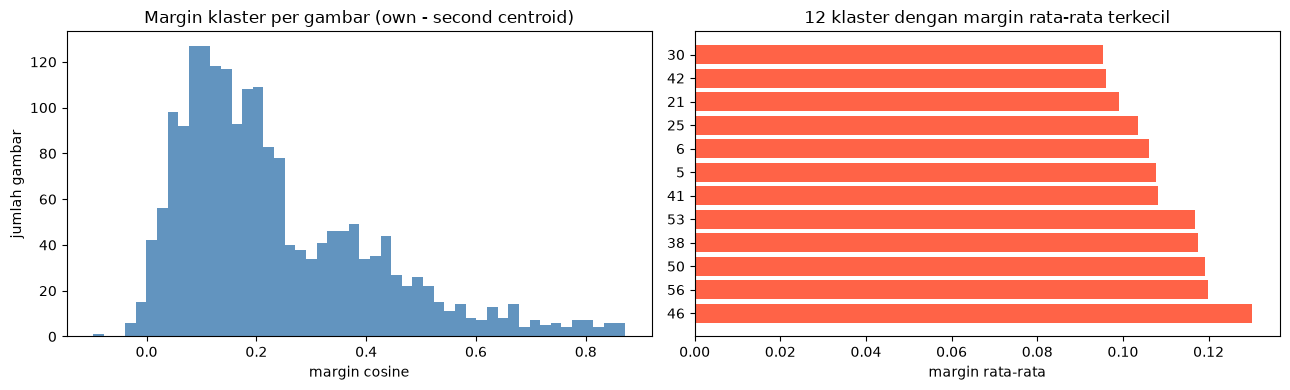

Klaster margin terendah (kuartil bawah): [30, 42, 21, 25, 6, 5, 41, 53, 38, 50, 56, 46, 23, 0, 13, 63]
Margin rata-rata seluruh gambar: 0.2342 | gambar margin < 0.05: 170
Disimpan: artifacts_nb/cluster_geometry_v1.csv


In [17]:
# ----------------------------
# 4.4 Kohesi dan ambiguitas klaster (label-free)
# ----------------------------
cos_to_cent = X_train_comb @ centroids.T
own_sim = cos_to_cent[np.arange(len(X_train_comb)), final_labels]
tmp = cos_to_cent.copy()
tmp[np.arange(len(tmp)), final_labels] = -np.inf
second_sim = tmp.max(axis=1)
margin = own_sim - second_sim

cluster_geom = (pd.DataFrame({"cluster": final_labels, "own_sim": own_sim, "margin": margin})
                .groupby("cluster")
                .agg(n=("own_sim", "size"), mean_own_sim=("own_sim", "mean"), mean_margin=("margin", "mean"))
                .reset_index()
                .sort_values("mean_margin"))
geom_path = ART_DIR / f"cluster_geometry_{CLUSTER_VERSION}.csv"
cluster_geom.to_csv(geom_path, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(margin, bins=50, color="steelblue", alpha=0.85)
axes[0].set_title("Margin klaster per gambar (own - second centroid)")
axes[0].set_xlabel("margin cosine"); axes[0].set_ylabel("jumlah gambar")
top = cluster_geom.head(12)[::-1]
axes[1].barh(top.cluster.astype(str), top.mean_margin, color="tomato")
axes[1].set_title("12 klaster dengan margin rata-rata terkecil")
axes[1].set_xlabel("margin rata-rata")
plt.tight_layout(); plt.show()

low_margin = cluster_geom[cluster_geom.mean_margin < cluster_geom.mean_margin.quantile(0.25)]
print(f"Klaster margin terendah (kuartil bawah): {low_margin.cluster.astype(int).tolist()}")
print(f"Margin rata-rata seluruh gambar: {margin.mean():.4f} | gambar margin < 0.05: {int((margin < 0.05).sum())}")
print(f"Disimpan: {geom_path.relative_to(ROOT)}")

**Insight.** Beberapa klaster punya margin yang sangat kecil, artinya gambar di dalamnya hampir sama dekat dengan dua pusat klaster. Klaster seperti ini tidak otomatis salah, tetapi mapping satu kelas per klaster menjadi lebih berisiko. Bab 7 akan mengukur risiko ini dari sisi lain: apakah gambar dalam klaster lebih dekat ke centroid kelasnya sendiri atau ke kelas lain.


## Bab 5 — Stabilitas klaster tanpa label

**Tujuan:** mengukur seberapa stabil klaster k=64 terhadap seed KMeans, subset fold, dan view fitur (DINOv2 vs ConvNeXt). Semua metrik adalah proksi struktur, **bukan akurasi**.

In [18]:
# ============================================================
# BAB 5 - STABILITAS KLaster TANPA LABEL
# ============================================================
print("Validasi Bab 5 memakai label-free proxies. Tidak ada akurasi yang diklaim.")

# ----------------------------
# 5.1 Stabilitas antar seed KMeans k=64
# ----------------------------
k64_seed_labels = [sens_labels[f"k64_s{rs}"] for rs in N_KMEANS_SEEDS]
aris_seed, nmis_seed = pairwise_ari_nmi(k64_seed_labels)
seed_ari_mean = float(aris_seed.mean()) if len(aris_seed) else np.nan
seed_ari_min = float(aris_seed.min()) if len(aris_seed) else np.nan
seed_nmi_mean = float(nmis_seed.mean()) if len(nmis_seed) else np.nan

print("5.1 ARI antar seed KMeans k=64:")
seed_mat = np.eye(len(N_KMEANS_SEEDS))
for i in range(len(N_KMEANS_SEEDS)):
    for j in range(i + 1, len(N_KMEANS_SEEDS)):
        seed_mat[i, j] = seed_mat[j, i] = adjusted_rand_score(k64_seed_labels[i], k64_seed_labels[j])
print(pd.DataFrame(seed_mat, index=[f"s{s}" for s in N_KMEANS_SEEDS],
                   columns=[f"s{s}" for s in N_KMEANS_SEEDS]).round(3).to_string())
print(f"ARI seed: mean={seed_ari_mean:.3f} | min={seed_ari_min:.3f} | NMI mean={seed_nmi_mean:.3f}")

Validasi Bab 5 memakai label-free proxies. Tidak ada akurasi yang diklaim.
5.1 ARI antar seed KMeans k=64:
       s42    s43    s44
s42  1.000  0.596  0.604
s43  0.596  1.000  0.611
s44  0.604  0.611  1.000
ARI seed: mean=0.604 | min=0.596 | NMI mean=0.851


In [19]:
# ----------------------------
# 5.2 Stabilitas antar fold: fit KMeans pada 4/5 train, prediksi semua gambar
# ----------------------------
fold_stab_path = ART_DIR / f"fold_stability_{STABILITY_VERSION}.csv"
fold_stab_labels_path = ART_DIR / f"fold_stability_labels_{STABILITY_VERSION}.npz"

if fold_stab_path.exists() and fold_stab_labels_path.exists() and not RUN_STABILITY:
    fold_stab = pd.read_csv(fold_stab_path)
    with np.load(fold_stab_labels_path) as z:
        fold_labels = {k: np.asarray(z[k], dtype=int) for k in z.files}
    print(f"Stabilitas fold dimuat: {fold_stab_path.relative_to(ROOT)}")
elif fold_stab_path.exists() and RUN_STABILITY:
    fold_stab = pd.read_csv(fold_stab_path)
    with np.load(fold_stab_labels_path) as z:
        fold_labels = {k: np.asarray(z[k], dtype=int) for k in z.files}
    print("RUN_STABILITY=True, tetapi file versi ini sudah ada. Tidak menimpa; naikkan STABILITY_VERSION untuk hitung ulang.")
else:
    print(f"Menghitung {N_SPLITS} fold x {len(CV_SEEDS)} seed KMeans k={N_CLUSTERS} ...")
    t0 = time.time()
    rows = []
    fold_labels = {}
    for s in CV_SEEDS:
        for f in range(N_SPLITS):
            mask = folds[f"fold_s{s}"].to_numpy() != f
            km = KMeans(n_clusters=N_CLUSTERS, n_init=2, random_state=SEED + 1000 * s + f).fit(X_train_comb[mask])
            lab = km.predict(X_train_comb).astype(int)
            key = f"s{s}_f{f}"
            fold_labels[key] = lab
            rows.append({
                "cv_seed": int(s),
                "fold": int(f),
                "ari_vs_final": float(adjusted_rand_score(final_labels, lab)),
                "nmi_vs_final": float(normalized_mutual_info_score(final_labels, lab)),
                "train_n": int(mask.sum()),
            })
            print(f"  {key}: selesai ({time.time()-t0:.0f}s)")
    fold_stab = pd.DataFrame(rows)
    fold_stab.to_csv(fold_stab_path, index=False)
    np.savez_compressed(fold_stab_labels_path, **fold_labels)
    print(f"Selesai dalam {time.time()-t0:.1f} detik: {fold_stab_path.relative_to(ROOT)}")

fold_keys = list(fold_labels.keys())
fold_labs = [fold_labels[k] for k in fold_keys]
aris_fold, nmis_fold = pairwise_ari_nmi(fold_labs)
fold_ari_mean = float(aris_fold.mean()) if len(aris_fold) else np.nan
fold_ari_min = float(aris_fold.min()) if len(aris_fold) else np.nan
fold_nmi_mean = float(nmis_fold.mean()) if len(nmis_fold) else np.nan
fold_vs_final_mean = float(fold_stab.ari_vs_final.mean())
fold_vs_final_min = float(fold_stab.ari_vs_final.min())

print(f"Stabilitas antar 15 model fold: ARI mean={fold_ari_mean:.3f} | min={fold_ari_min:.3f} | NMI mean={fold_nmi_mean:.3f}")
print(f"ARI setiap model fold vs klaster final: mean={fold_vs_final_mean:.3f} | min={fold_vs_final_min:.3f}")

RUN_STABILITY=True, tetapi file versi ini sudah ada. Tidak menimpa; naikkan STABILITY_VERSION untuk hitung ulang.


Stabilitas antar 15 model fold: ARI mean=0.600 | min=0.542 | NMI mean=0.844
ARI setiap model fold vs klaster final: mean=0.627 | min=0.582


In [20]:
# ----------------------------
# 5.3 Cross-view: DINOv2 vs ConvNeXt
# ----------------------------
cross_path = ART_DIR / f"cross_view_{STABILITY_VERSION}.json"

if cross_path.exists() and not RUN_STABILITY:
    cross_view = json.loads(cross_path.read_text(encoding="utf-8"))
    print(f"Cross-view dimuat: {cross_path.relative_to(ROOT)}")
else:
    print(f"Menghitung cross-view k={N_CLUSTERS} untuk DINOv2 dan ConvNeXt ...")
    t0 = time.time()
    view_labels = {}
    view_purity = {}
    for view in ("dinov2", "convnext"):
        view_labels[view] = []
        view_purity[view] = []
        for rs in N_KMEANS_SEEDS:
            km = KMeans(n_clusters=N_CLUSTERS, n_init=3, random_state=rs).fit(features[view]["train"])
            lab = km.labels_.astype(int)
            view_labels[view].append(lab)
            view_purity[view].append(macro_purity(lab, folds.proxy_class.to_numpy()))
            print(f"  {view} seed={rs}: selesai ({time.time()-t0:.0f}s)")

    # Stabilitas internal tiap view.
    view_seed_ari = {}
    for view in ("dinov2", "convnext"):
        aris, _ = pairwise_ari_nmi(view_labels[view])
        view_seed_ari[view] = {"mean": float(aris.mean()), "min": float(aris.min())} if len(aris) else {"mean": np.nan, "min": np.nan}

    # Kesepakatan antar view pada seed yang sama.
    cross_aris, cross_nmis = [], []
    for i in range(len(N_KMEANS_SEEDS)):
        cross_aris.append(adjusted_rand_score(view_labels["dinov2"][i], view_labels["convnext"][i]))
        cross_nmis.append(normalized_mutual_info_score(view_labels["dinov2"][i], view_labels["convnext"][i]))

    # Jaccard 10-NN antar view.
    nbr_d = knn_indices(features["dinov2"]["train"], k=10)
    nbr_c = knn_indices(features["convnext"]["train"], k=10)
    jac = []
    for a, b in zip(nbr_d, nbr_c):
        sa, sb = set(a.tolist()), set(b.tolist())
        jac.append(len(sa & sb) / len(sa | sb))
    jac = np.array(jac, dtype=float)

    # Perbandingan klaster gabungan vs tiap view (seed 42).
    comb_vs_view = {}
    for view in ("dinov2", "convnext"):
        comb_vs_view[view] = float(adjusted_rand_score(final_labels, view_labels[view][0]))

    cross_view = {
        "created_at": RUN_TS,
        "k": N_CLUSTERS,
        "kmeans_seeds": N_KMEANS_SEEDS,
        "dinov2": {
            "seed_ari_mean": view_seed_ari["dinov2"]["mean"],
            "seed_ari_min": view_seed_ari["dinov2"]["min"],
            "purity_mean": float(np.mean(view_purity["dinov2"])),
        },
        "convnext": {
            "seed_ari_mean": view_seed_ari["convnext"]["mean"],
            "seed_ari_min": view_seed_ari["convnext"]["min"],
            "purity_mean": float(np.mean(view_purity["convnext"])),
        },
        "cross_view_ari_mean": float(np.mean(cross_aris)),
        "cross_view_ari_min": float(np.min(cross_aris)),
        "cross_view_nmi_mean": float(np.mean(cross_nmis)),
        "knn10_jaccard_mean": float(jac.mean()),
        "knn10_jaccard_p10": float(np.percentile(jac, 10)),
        "combined_vs_dinov2_ari": comb_vs_view["dinov2"],
        "combined_vs_convnext_ari": comb_vs_view["convnext"],
        "note": "ARI/NMI/Jaccard measure structural agreement, not class accuracy.",
    }
    save_json(cross_view, cross_path)
    print(f"Selesai dalam {time.time()-t0:.1f} detik: {cross_path.relative_to(ROOT)}")

print("\nCross-view (proksi struktur, bukan akurasi):")
print(f"- DINOv2   : seed ARI mean={cross_view['dinov2']['seed_ari_mean']:.3f} | purity={cross_view['dinov2']['purity_mean']:.3f}")
print(f"- ConvNeXt : seed ARI mean={cross_view['convnext']['seed_ari_mean']:.3f} | purity={cross_view['convnext']['purity_mean']:.3f}")
print(f"- DINOv2 vs ConvNeXt: ARI mean={cross_view['cross_view_ari_mean']:.3f} | NMI mean={cross_view['cross_view_nmi_mean']:.3f}")
print(f"- 10-NN Jaccard antar view: mean={cross_view['knn10_jaccard_mean']:.3f} | p10={cross_view['knn10_jaccard_p10']:.3f}")
print(f"- Gabungan vs DINOv2 ARI={cross_view['combined_vs_dinov2_ari']:.3f} | vs ConvNeXt ARI={cross_view['combined_vs_convnext_ari']:.3f}")

Menghitung cross-view k=64 untuk DINOv2 dan ConvNeXt ...


  dinov2 seed=42: selesai (1s)


  dinov2 seed=43: selesai (1s)


  dinov2 seed=44: selesai (2s)


  convnext seed=42: selesai (2s)


  convnext seed=43: selesai (3s)


  convnext seed=44: selesai (4s)
Selesai dalam 4.1 detik: artifacts_nb/cross_view_v1.json

Cross-view (proksi struktur, bukan akurasi):
- DINOv2   : seed ARI mean=0.671 | purity=0.920
- ConvNeXt : seed ARI mean=0.608 | purity=0.916
- DINOv2 vs ConvNeXt: ARI mean=0.457 | NMI mean=0.763
- 10-NN Jaccard antar view: mean=0.367 | p10=0.111
- Gabungan vs DINOv2 ARI=0.575 | vs ConvNeXt ARI=0.594


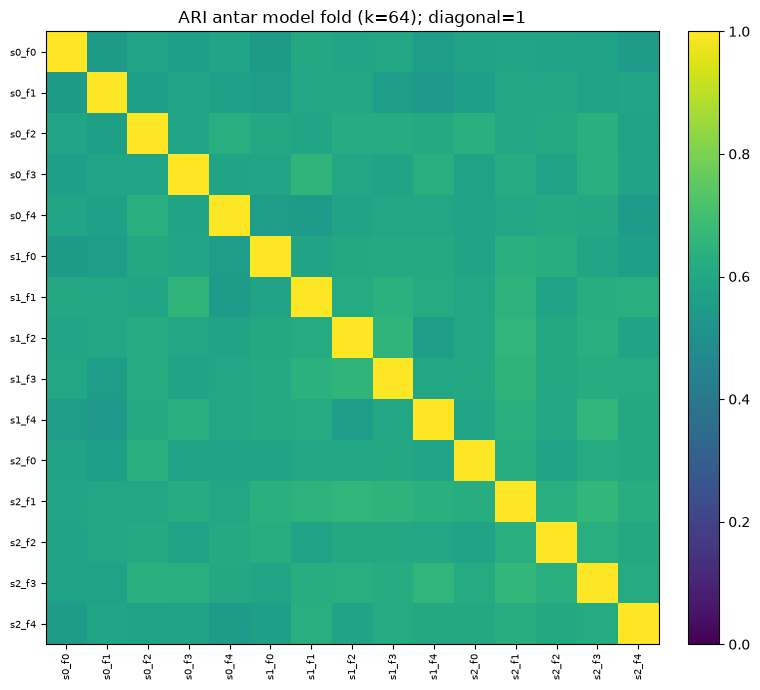

RINGKASAN BAB 5 - STABILITAS TANPA LABEL
- ARI antar seed k=64: mean=0.604, min=0.596, NMI mean=0.851.
- ARI antar 15 fold: mean=0.600, min=0.542; vs final mean=0.627.
- Cross-view ARI=0.457; 10-NN Jaccard=0.367.
- Purity proxy=0.928; silhouette=0.187; neighbor consistency=0.783.
PERINGATAN (bukan kegagalan): ARI antar seed rendah (0.604 < 0.80); ARI antar fold rendah (0.600 < 0.70)
  Artinya struktur klaster kurang stabil. Jangan menafsirkan ini sebagai akurasi rendah/tinggi; ini hanya sinyal risiko.
- Gate 5: LULUS - semua metrik proksi terhitung dan dilaporkan.
Batas tafsir: klaster yang stabil bisa stabil-salah. Tidak ada label manual per gambar di pipeline ini.


In [21]:
# ----------------------------
# 5.4 Heatmap ARI antar 15 model fold
# ----------------------------
ari_mat = np.eye(len(fold_keys))
for i in range(len(fold_keys)):
    for j in range(i + 1, len(fold_keys)):
        ari_mat[i, j] = ari_mat[j, i] = adjusted_rand_score(fold_labs[i], fold_labs[j])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(ari_mat, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(fold_keys))); ax.set_xticklabels(fold_keys, rotation=90, fontsize=7)
ax.set_yticks(range(len(fold_keys))); ax.set_yticklabels(fold_keys, fontsize=7)
ax.set_title("ARI antar model fold (k=64); diagonal=1")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig_path = ART_DIR / f"fig_fold_ari_{STABILITY_VERSION}.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()

# ----------------------------
# 5.5 Ringkasan + gate + peringatan
# ----------------------------
warnings_list = []
if seed_ari_mean < 0.80:
    warnings_list.append(f"ARI antar seed rendah ({seed_ari_mean:.3f} < 0.80)")
if fold_ari_mean < 0.70:
    warnings_list.append(f"ARI antar fold rendah ({fold_ari_mean:.3f} < 0.70)")
if cross_view["cross_view_ari_mean"] < 0.40:
    warnings_list.append(f"ARI cross-view rendah ({cross_view['cross_view_ari_mean']:.3f} < 0.40)")
if purity_final < 0.80:
    warnings_list.append(f"purity proxy rendah ({purity_final:.3f} < 0.80)")

print("RINGKASAN BAB 5 - STABILITAS TANPA LABEL")
print(f"- ARI antar seed k=64: mean={seed_ari_mean:.3f}, min={seed_ari_min:.3f}, NMI mean={seed_nmi_mean:.3f}.")
print(f"- ARI antar 15 fold: mean={fold_ari_mean:.3f}, min={fold_ari_min:.3f}; vs final mean={fold_vs_final_mean:.3f}.")
print(f"- Cross-view ARI={cross_view['cross_view_ari_mean']:.3f}; 10-NN Jaccard={cross_view['knn10_jaccard_mean']:.3f}.")
print(f"- Purity proxy={purity_final:.3f}; silhouette={sil_final:.3f}; neighbor consistency={cons_final:.3f}.")
if warnings_list:
    print("PERINGATAN (bukan kegagalan): " + "; ".join(warnings_list))
    print("  Artinya struktur klaster kurang stabil. Jangan menafsirkan ini sebagai akurasi rendah/tinggi; ini hanya sinyal risiko.")
else:
    print("- Tidak ada peringatan ambang stabilitas.")
print("- Gate 5: LULUS - semua metrik proksi terhitung dan dilaporkan.")
print("Batas tafsir: klaster yang stabil bisa stabil-salah. Tidak ada label manual per gambar di pipeline ini.")

### 5.6 Scorecard stabilitas: apa yang terbukti dan apa yang tidak

Semua angka di Bab 5 adalah proksi struktur. Tabel ini merangkumnya dalam satu tempat agar tidak ada yang salah tafsir: ARI/NMI tinggi berarti solusi clustering mirip, bukan berarti kelasnya benar.

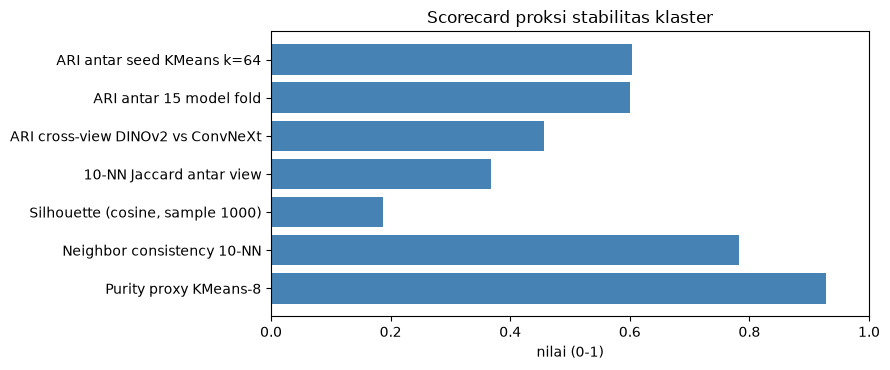

                       diagnostik  nilai                                         tafsir
       ARI antar seed KMeans k=64 0.6035 mendekati 1 berarti solusi klaster makin mirip
          ARI antar 15 model fold 0.6001               stabilitas terhadap subset train
ARI cross-view DINOv2 vs ConvNeXt 0.4568            dua view setuju pada struktur kasar
         10-NN Jaccard antar view 0.3673             tetangga terdekat mirip antar view
 Silhouette (cosine, sample 1000) 0.1870                              pemisahan klaster
       Neighbor consistency 10-NN 0.7826                  tetangga cenderung seklauster
            Purity proxy KMeans-8 0.9283         konsistensi terhadap proxy tanpa label
Disimpan: artifacts_nb/stability_scorecard_v1.csv
PENTING: tidak ada baris ini yang berarti akurasi. Semua mengukur struktur, bukan kebenaran kelas.


In [22]:
# ----------------------------
# 5.6 Scorecard stabilitas (proksi, bukan akurasi)
# ----------------------------
scorecard = pd.DataFrame([
    {"diagnostik": "ARI antar seed KMeans k=64", "nilai": seed_ari_mean,
     "tafsir": "mendekati 1 berarti solusi klaster makin mirip"},
    {"diagnostik": "ARI antar 15 model fold", "nilai": fold_ari_mean,
     "tafsir": "stabilitas terhadap subset train"},
    {"diagnostik": "ARI cross-view DINOv2 vs ConvNeXt", "nilai": cross_view["cross_view_ari_mean"],
     "tafsir": "dua view setuju pada struktur kasar"},
    {"diagnostik": "10-NN Jaccard antar view", "nilai": cross_view["knn10_jaccard_mean"],
     "tafsir": "tetangga terdekat mirip antar view"},
    {"diagnostik": "Silhouette (cosine, sample 1000)", "nilai": sil_final,
     "tafsir": "pemisahan klaster"},
    {"diagnostik": "Neighbor consistency 10-NN", "nilai": cons_final,
     "tafsir": "tetangga cenderung seklauster"},
    {"diagnostik": "Purity proxy KMeans-8", "nilai": purity_final,
     "tafsir": "konsistensi terhadap proxy tanpa label"},
])
scorecard["nilai"] = scorecard["nilai"].round(4)
score_path = ART_DIR / f"stability_scorecard_{STABILITY_VERSION}.csv"
scorecard.to_csv(score_path, index=False)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(scorecard.diagnostik[::-1], scorecard.nilai[::-1], color="steelblue")
ax.set_xlim(0, 1); ax.set_xlabel("nilai (0-1)")
ax.set_title("Scorecard proksi stabilitas klaster")
plt.tight_layout(); plt.show()
print(scorecard.to_string(index=False))
print(f"Disimpan: {score_path.relative_to(ROOT)}")
print("PENTING: tidak ada baris ini yang berarti akurasi. Semua mengukur struktur, bukan kebenaran kelas.")

## Bab 6 — Sanity check duplikat & audit fitur

**Tujuan:** memastikan tiga pasangan duplikat piksel train-test benar-benar identik di ruang fitur, dan memeriksa apakah assignment klasternya konsisten. Ini pemeriksaan bug, bukan evaluasi akurasi.

In [23]:
# ============================================================
# BAB 6 - SANITY CHECK DUPLIKAT & AUDIT FITUR
# ============================================================
pairs_path = ART_DIR / "train_test_exact_pairs.csv"
require(pairs_path.exists(), "train_test_exact_pairs.csv tidak ada. Jalankan Bab 1 dulu.")
pairs = pd.read_csv(pairs_path)
require(len(pairs) > 0, "Tidak ada pasangan duplikat train-test untuk diperiksa.")

train_pos = {f: i for i, f in enumerate(train_df.filename)}
test_pos = {f: i for i, f in enumerate(test_df.filename)}
test_cluster = np.argmax(X_test_comb @ centroids.T, axis=1)

# Tetangga terdekat train untuk setiap gambar test duplikat.
nn_d = NearestNeighbors(n_neighbors=1, metric="cosine").fit(features["dinov2"]["train"])
nn_c = NearestNeighbors(n_neighbors=1, metric="cosine").fit(features["convnext"]["train"])

rows = []
for _, r in pairs.iterrows():
    ti = train_pos[r.train_filename]
    ei = test_pos[r.test_filename]
    cos_d = float(features["dinov2"]["train"][ti] @ features["dinov2"]["test"][ei])
    cos_c = float(features["convnext"]["train"][ti] @ features["convnext"]["test"][ei])
    cos_x = float(X_train_comb[ti] @ X_test_comb[ei])
    dist_d, ind_d = nn_d.kneighbors(features["dinov2"]["test"][ei:ei+1], n_neighbors=1)
    dist_c, ind_c = nn_c.kneighbors(features["convnext"]["test"][ei:ei+1], n_neighbors=1)
    top1_d = train_df.filename.iloc[int(ind_d[0, 0])]
    top1_c = train_df.filename.iloc[int(ind_c[0, 0])]
    cl_tr = int(train_clusters.cluster.iloc[ti])
    cl_te = int(test_cluster[ei])
    rows.append({
        "train_filename": r.train_filename,
        "test_filename": r.test_filename,
        "cos_dinov2": cos_d,
        "cos_convnext": cos_c,
        "cos_combined": cos_x,
        "cluster_train": cl_tr,
        "cluster_test": cl_te,
        "cluster_match": bool(cl_tr == cl_te),
        "top1_train_dinov2": top1_d,
        "top1_is_pair_dinov2": bool(top1_d == r.train_filename),
        "top1_train_convnext": top1_c,
        "top1_is_pair_convnext": bool(top1_c == r.train_filename),
    })

dup_sanity = pd.DataFrame(rows)
dup_path = ART_DIR / f"duplicate_sanity_{STABILITY_VERSION}.csv"
dup_sanity.to_csv(dup_path, index=False)

norm_tr = np.linalg.norm(X_train_comb, axis=1)
norm_te = np.linalg.norm(X_test_comb, axis=1)
finite_ok = bool(np.isfinite(X_train_comb).all() and np.isfinite(X_test_comb).all())
norm_ok = bool(np.abs(norm_tr - 1).max() < 1e-3 and np.abs(norm_te - 1).max() < 1e-3)
cos_ok = bool(dup_sanity.cos_combined.min() >= 0.999)

print("SANITY CHECK DUPLIKAT TRAIN-TEST")
print(dup_sanity[["train_filename", "test_filename", "cos_dinov2", "cos_convnext", "cos_combined",
                  "cluster_train", "cluster_test", "cluster_match",
                  "top1_is_pair_dinov2", "top1_is_pair_convnext"]].round(6).to_string(index=False))
print(f"\nNorma fitur gabungan: train min/max={norm_tr.min():.6f}/{norm_tr.max():.6f} | "
      f"test min/max={norm_te.min():.6f}/{norm_te.max():.6f}")
print(f"Finite={finite_ok} | norm_ok={norm_ok} | cosine>=0.999={cos_ok}")
if not dup_sanity.cluster_match.all():
    print("PERINGATAN: ada pasangan identik yang jatuh ke klaster berbeda. Ini biasanya efek batas klaster, bukan bug fitur.")
if not (dup_sanity.top1_is_pair_dinov2.all() and dup_sanity.top1_is_pair_convnext.all()):
    print("PERINGATAN: tetangga terdekat bukan pasangan identik. Periksa cache fitur/urutan file.")

save_json({
    "created_at": RUN_TS,
    "n_pairs": int(len(dup_sanity)),
    "cos_combined_min": float(dup_sanity.cos_combined.min()),
    "all_cluster_match": bool(dup_sanity.cluster_match.all()),
    "all_top1_pair_dinov2": bool(dup_sanity.top1_is_pair_dinov2.all()),
    "all_top1_pair_convnext": bool(dup_sanity.top1_is_pair_convnext.all()),
    "finite_ok": finite_ok,
    "norm_ok": norm_ok,
    "note": "Three exact duplicate pairs are a bug check, not an accuracy estimate.",
}, ART_DIR / f"duplicate_sanity_{STABILITY_VERSION}.json")

require(finite_ok and norm_ok and cos_ok,
        "Sanity check duplikat gagal: fitur tidak finite/normalized atau cosine <0.999. "
        "Jangan lanjut sebelum cache fitur diperiksa.")

print("\nRINGKASAN BAB 6 - SANITY DUPLIKAT")
print(f"- {len(dup_sanity)} pasangan diperiksa; cosine gabungan min={dup_sanity.cos_combined.min():.6f}.")
print(f"- Klaster sama: {int(dup_sanity.cluster_match.sum())}/{len(dup_sanity)}; top-1 tetangga benar (DINOv2): "
      f"{int(dup_sanity.top1_is_pair_dinov2.sum())}/{len(dup_sanity)}.")
print("- Gate 6: LULUS - fitur identik dan audit numerik bersih.")
print("Batas tafsir: tiga pasangan hanya mendeteksi bug ekstraksi/urutan, bukan menjamin kualitas model.")

SANITY CHECK DUPLIKAT TRAIN-TEST
train_filename test_filename  cos_dinov2  cos_convnext  cos_combined  cluster_train  cluster_test  cluster_match  top1_is_pair_dinov2  top1_is_pair_convnext
      1046.jpg       017.jpg         1.0           1.0           1.0             22            22           True                 True                   True
      1135.jpg       201.jpg         1.0           1.0           1.0             22            22           True                 True                   True
      1821.jpg       042.jpg         1.0           1.0           1.0             63            63           True                 True                   True

Norma fitur gabungan: train min/max=1.000000/1.000000 | test min/max=1.000000/1.000000
Finite=True | norm_ok=True | cosine>=0.999=True

RINGKASAN BAB 6 - SANITY DUPLIKAT
- 3 pasangan diperiksa; cosine gabungan min=1.000000.
- Klaster sama: 3/3; top-1 tetangga benar (DINOv2): 3/3.
- Gate 6: LULUS - fitur identik dan audit numerik bersih.

## Bab 7 — PEMETAAN KLASTER OTOMATIS (MODEL-BASED)

**Tujuan:** memetakan **64 klaster** ke 8 nama kelas 

1. `convnext_large.fb_in22k_ft_in1k_384` (ImageNet-1k, pretrained) memprediksi kelas ImageNet setiap gambar train.
2. Leksikon ontologi ImageNet→kelas sampah (kamus tetap, bukan pelabelan per klaster) mengubah probabilitas itu menjadi skor 8 kelas.
3. Prototipe kelas di ruang fitur DINOv2+ConvNeXt, diseed skor ImageNet, memperbaiki klaster dengan margin rendah (self-training 2 putaran).


**Output:** `labeling/cluster_to_class_model_v1.csv` + bukti `artifacts_nb/cluster_model_label_evidence_v1.json`. Regenerasi: `python tools/model_cluster_labeling.py`.

**Batas tafsir:** mapping tetap pseudo-label, bukan ground truth. Kolom `confidence`, `margin`, `status`, dan `top_imagenet` menandai klaster rapuh; Bab 8–9 tidak boleh menyebut hasilnya sebagai akurasi.


Tabel bantuan: artifacts_nb/cluster_help_k64_v1.csv
Isi tabel (klaster, jumlah gambar, contoh 4 file terdekat centroid):
 cluster  n  mean_dist                                  examples
       0  8   0.774638   1167.jpg; 1097.jpeg; 1826.jpg; 1185.jpg
       1 48   0.770106    0325.jpg; 0379.jpg; 1780.jpg; 1249.jpg
       2 74   0.588065    0297.jpg; 1611.jpg; 0077.jpg; 0483.jpg
       3 34   0.795506 0760.jpeg; 0108.jpeg; 0968.jpg; 0799.jpeg
       4 29   0.699859    1370.jpg; 0080.jpg; 1035.jpg; 0142.jpg
       5 11   0.688718    0307.jpg; 0855.jpg; 1544.jpg; 0465.jpg
       6 59   0.688000    0537.jpg; 1095.jpg; 1679.jpg; 1489.jpg
       7 24   0.627996    1280.jpg; 1901.jpg; 0249.jpg; 0382.jpg
       8 55   0.694416    0447.jpg; 1260.jpg; 1047.jpg; 0788.jpg
       9 10   0.826710    1084.jpg; 0245.jpg; 0274.jpg; 1818.jpg
      10 12   0.625125    0146.jpg; 0281.jpg; 1909.jpg; 0648.jpg
      11 39   0.640074    1754.jpg; 0840.jpg; 1358.jpg; 1373.jpg
      12 41   0.672166    0883.jpg

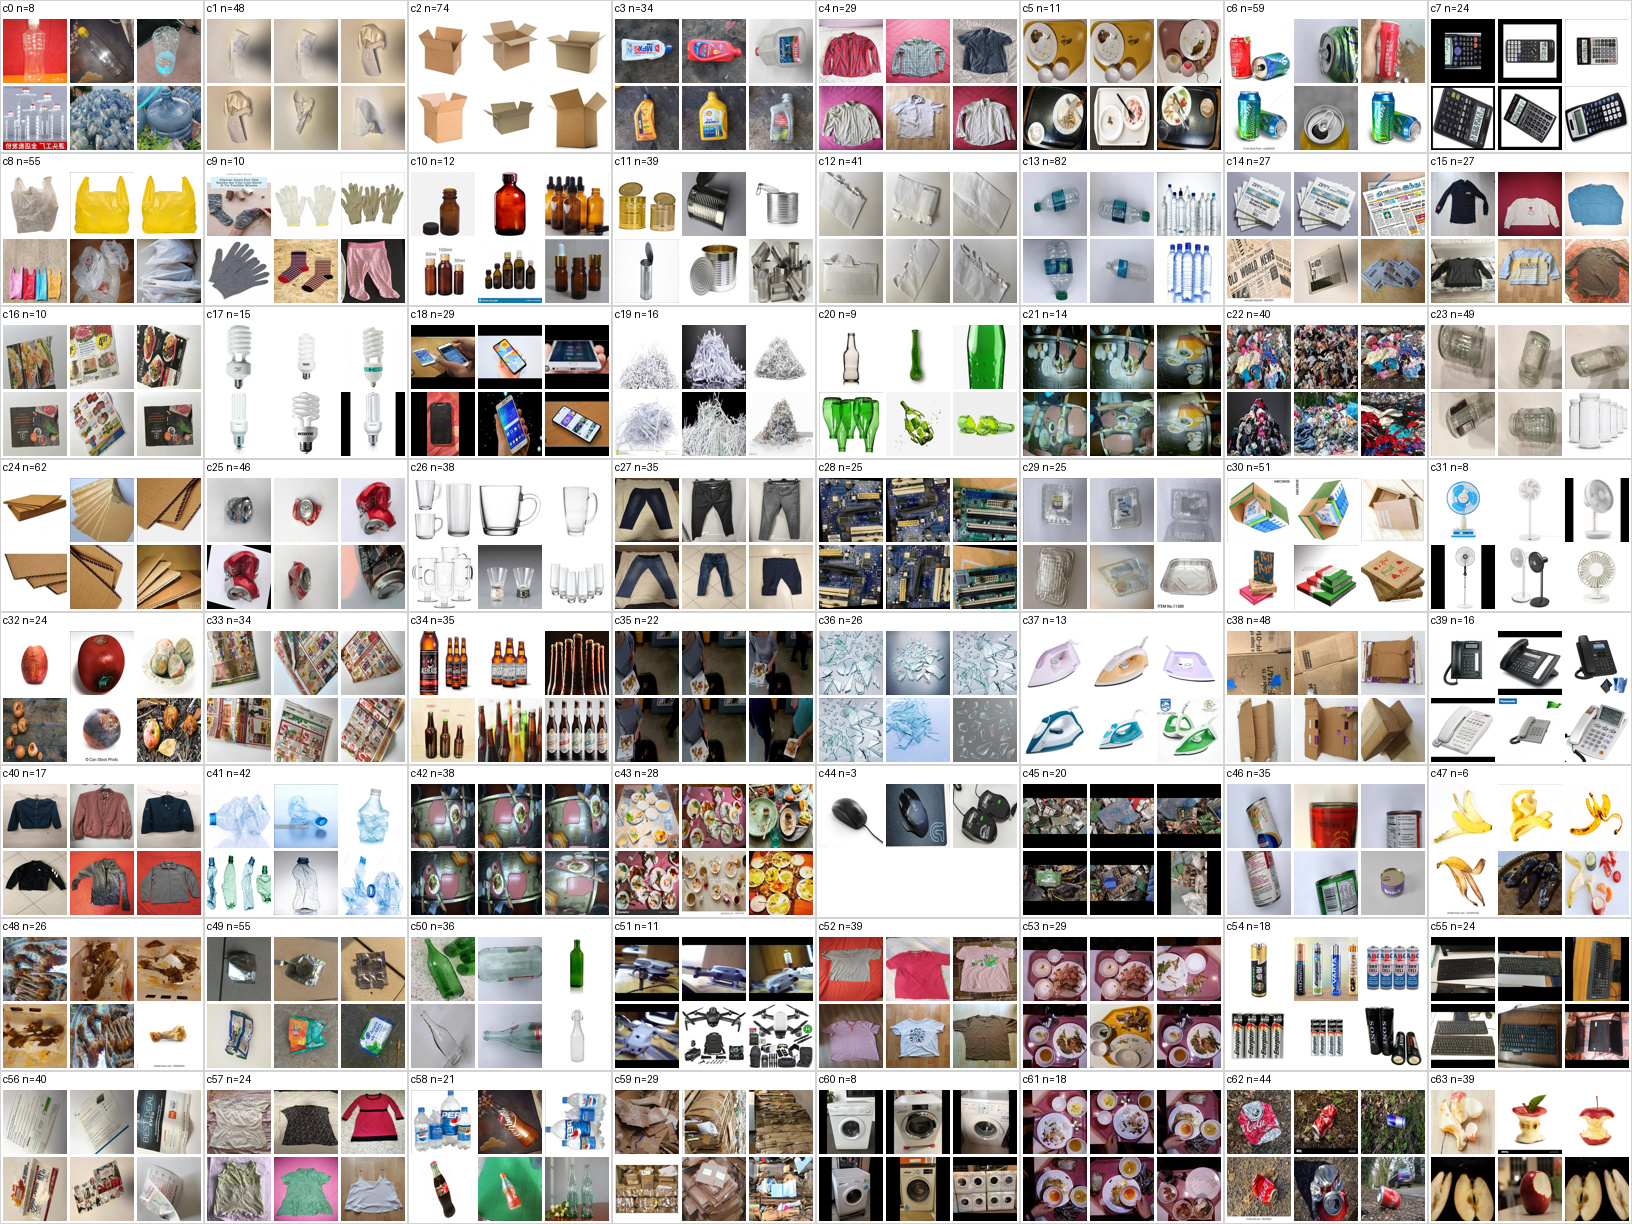

In [24]:
# ============================================================
# BAB 7 - MAPPING KLaster -> KELAS
# ============================================================
from PIL import ImageDraw
from IPython.display import display, Image as IPImage

# ----------------------------
# 7.1 Tabel bantuan + contact sheet (audit visual, bukan input model)
# ----------------------------
help_rows = []
examples_by_cluster = {}
for c in range(N_CLUSTERS):
    sub = train_clusters[train_clusters.cluster == c].sort_values("dist_to_center")
    files = sub.filename.head(6).tolist()
    examples_by_cluster[c] = files
    help_rows.append({
        "cluster": int(c),
        "n": int(len(sub)),
        "mean_dist": float(sub.dist_to_center.mean()),
        "examples": "; ".join(files[:4]),
    })
cluster_help = pd.DataFrame(help_rows)
help_path = ART_DIR / f"cluster_help_k64_{MAPPING_VERSION}.csv"
cluster_help.to_csv(help_path, index=False)

sheet_path = ART_DIR / f"fig_cluster_contact_k64_{MAPPING_VERSION}.png"
if not sheet_path.exists():
    TH, COLS, ROWS, PAD, LABEL_H, GRID = 64, 3, 2, 3, 16, 8
    tile_w = COLS * TH + (COLS + 1) * PAD
    tile_h = ROWS * TH + (ROWS + 1) * PAD + LABEL_H

    def _thumb(path):
        return load_image(ROOT / path if not Path(path).is_absolute() else Path(path)).resize((TH, TH))

    canvas = Image.new("RGB", (GRID * tile_w, GRID * tile_h), "white")
    draw = ImageDraw.Draw(canvas)
    for c in range(N_CLUSTERS):
        gx, gy = c % GRID, c // GRID
        x0, y0 = gx * tile_w, gy * tile_h
        draw.rectangle([x0, y0, x0 + tile_w - 1, y0 + tile_h - 1], outline="lightgray")
        draw.text((x0 + 3, y0 + 2), f"c{c} n={int(cluster_help.loc[c, 'n'])}", fill="black")
        sub = train_clusters[train_clusters.cluster == c].sort_values("dist_to_center")
        for k, (_, r) in enumerate(sub.head(6).iterrows()):
            col, row = k % COLS, k // COLS
            th = _thumb(r["path"])
            canvas.paste(th, (x0 + PAD + col * (TH + PAD), y0 + LABEL_H + PAD + row * (TH + PAD)))
    canvas.save(sheet_path)
    print(f"Contact sheet dibuat: {sheet_path.relative_to(ROOT)}")

print(f"Tabel bantuan: {help_path.relative_to(ROOT)}")
print("Isi tabel (klaster, jumlah gambar, contoh 4 file terdekat centroid):")
print(cluster_help.to_string(index=False))
print("\nContact sheet 64 klaster (audit visual; 6 gambar terdekat centroid per klaster):")
display(IPImage(filename=str(sheet_path)))

In [25]:
# ----------------------------
# 7.2 Muat mapping hasil model: 64 klaster -> 8 kelas
# ----------------------------

model_map_path = LABEL_DIR / "cluster_to_class_model_v1.csv"
require(model_map_path.exists(),
        f"Mapping model belum ada: {model_map_path}. Jalankan tools/model_cluster_labeling.py.")

model_mapping_df = pd.read_csv(model_map_path)
require({"cluster", "class"} <= set(model_mapping_df.columns),
        "Mapping model harus punya kolom cluster dan class.")
model_mapping_df["cluster"] = pd.to_numeric(model_mapping_df["cluster"], errors="raise")
model_mapping_df["class"] = model_mapping_df["class"].astype(str).str.strip().str.lower()
mapping = dict(zip(model_mapping_df.cluster.astype(int), model_mapping_df["class"]))
mapping_ok = False  # divalidasi di 7.3

evidence_path = ART_DIR / "cluster_model_label_evidence_v1.json"
if evidence_path.exists():
    evidence = json.loads(evidence_path.read_text(encoding="utf-8"))
    print("Sumber mapping:", evidence_path.relative_to(ROOT))
    print("Model semantik :", evidence.get("semantic_model"))
    print("Ruang fitur    :", evidence.get("feature_space"))
    print("Seed per kelas :", evidence.get("prototype_self_training", {}).get("seeds_per_class"))
print(f"Mapping model dimuat: {len(mapping)} klaster dari {model_map_path.relative_to(ROOT)}.")


Mapping model dimuat: 64 klaster dari labeling/cluster_to_class_model_v1.csv.


In [26]:
# ----------------------------
# 7.3 Validasi mapping model + turunkan pseudo-label per gambar
# ----------------------------
problems = []
map_path = model_map_path
mapping_source = "model: imagenet_convnext_lexicon_prototype"

if len(mapping) != N_CLUSTERS:
    problems.append(f"Mapping berisi {len(mapping)} klaster, seharusnya {N_CLUSTERS}.")
if set(mapping) != set(range(N_CLUSTERS)):
    problems.append("Mapping harus berisi tepat cluster 0..63, masing-masing sekali.")
bad = sorted(set(mapping.values()) - set(CLASSES))
if bad:
    problems.append(f"Kelas tidak dikenal: {bad}. Gunakan nama kelas: {CLASSES}.")
if problems:
    raise AssertionError(
        "MAPPING MODEL TIDAK VALID: " + " | ".join(problems) +
        " Jalankan ulang: python tools/model_cluster_labeling.py"
    )
mapping_ok = True

audit = pd.read_csv(model_map_path)
if "prototype_override" in audit.columns:
    n_prototype_override = int(audit["prototype_override"].astype(str).str.lower().eq("true").sum())
else:
    n_prototype_override = 0
weak = audit[audit["status"] != "confident"] if "status" in audit.columns else audit.iloc[0:0]
print("MAPPING MODEL VALID - 64 klaster, 8 kelas")
print(f"Sumber        : {map_path.relative_to(ROOT)}")
print("Metode        : ImageNet-1k vision-only -> leksikon ontologi -> prototipe fitur (self-training)")
print(f"Override      : {n_prototype_override} klaster digeser prototipe dari kelas semantik")
print(f"Klaster lemah : {[int(c) for c in weak.cluster.tolist()] if len(weak) else 'tidak ada'} (margin < 0.15)")
print()
print(pd.DataFrame({"cluster": sorted(mapping), "class": [mapping[c] for c in sorted(mapping)]}).to_string(index=False))

# ----------------------------
# 7.3 Mapping lengkap: turunkan pseudo-label per gambar (bukan label manual)
# ----------------------------
train_clusters["pseudo_class"] = train_clusters.cluster.map(mapping)
require(train_clusters.pseudo_class.notna().all(), "Ada klaster tanpa mapping setelah validasi.")

# --- override sub-cluster (mulai) ---
# 7.3b (opsional) Override sub-cluster: keputusan tingkat grup, bukan per gambar
sub_override_path = LABEL_DIR / f"subcluster_to_class_{MAPPING_VERSION}.csv"
subclusters_path = ART_DIR / "subclusters_v1.csv"
r2_override_path = LABEL_DIR / f"subcluster_to_class_{MAPPING_VERSION}_round2.csv"
r2_sub_path = ART_DIR / "subclusters_v1_round2.csv"
n_sub_override = 0
n_sub_rows = 0
n_sub_mixed = 0
if sub_override_path.exists() and subclusters_path.exists():
    so = pd.read_csv(sub_override_path)
    sc = pd.read_csv(subclusters_path)
    cols_ok = ({"cluster", "subcluster", "new_class"} <= set(so.columns)
               and {"filename", "cluster", "subcluster"} <= set(sc.columns))
    if cols_ok:
        so["new_class"] = so["new_class"].astype("string").str.strip().str.lower()
        so = so[so["new_class"].notna() & (so["new_class"] != "")]
        n_sub_mixed = int((so["new_class"] == "mixed").sum())
        so = so[so["new_class"].isin(CLASSES)]
        n_sub_rows = int(len(so))
        if n_sub_rows:
            lut = {(int(r.cluster), int(r.subcluster)): r.new_class for r in so.itertuples()}
            sc["_new"] = [lut.get((int(c), int(s))) for c, s in zip(sc.cluster, sc.subcluster)]
            hit = sc["_new"].notna()
            file_to_class = dict(zip(sc.loc[hit, "filename"], sc.loc[hit, "_new"]))
            mask = train_clusters.filename.isin(file_to_class)
            train_clusters.loc[mask, "pseudo_class"] = train_clusters.loc[mask, "filename"].map(file_to_class)
            n_sub_override = int(mask.sum())
    require(train_clusters.pseudo_class.isin(CLASSES).all(),
            "Override sub-cluster menghasilkan kelas tidak dikenal.")

# Putaran 2 (opsional): pecah lebih halus sub-cluster yang masih MIXED di putaran 1.
# Tetap keputusan tingkat grup (3-4 gambar), bukan label per gambar.
n_r2_override = 0
n_r2_rows = 0
n_r2_mixed = 0
if r2_override_path.exists() and r2_sub_path.exists():
    so2 = pd.read_csv(r2_override_path)
    sc2 = pd.read_csv(r2_sub_path)
    cols_ok2 = ({"cluster", "subcluster", "round2", "new_class"} <= set(so2.columns)
                and {"filename", "cluster", "subcluster", "round2"} <= set(sc2.columns))
    if cols_ok2:
        so2["new_class"] = so2["new_class"].astype("string").str.strip().str.lower()
        so2 = so2[so2["new_class"].notna() & (so2["new_class"] != "")]
        n_r2_mixed = int((so2["new_class"] == "mixed").sum())
        so2 = so2[so2["new_class"].isin(CLASSES)]
        n_r2_rows = int(len(so2))
        if n_r2_rows:
            lut2 = {(int(r.cluster), int(r.subcluster), int(r.round2)): r.new_class for r in so2.itertuples()}
            sc2["_new"] = [lut2.get((int(c), int(s), int(k)))
                           for c, s, k in zip(sc2.cluster, sc2.subcluster, sc2.round2)]
            hit2 = sc2["_new"].notna()
            file_to_class2 = dict(zip(sc2.loc[hit2, "filename"], sc2.loc[hit2, "_new"]))
            mask2 = train_clusters.filename.isin(file_to_class2)
            train_clusters.loc[mask2, "pseudo_class"] = train_clusters.loc[mask2, "filename"].map(file_to_class2)
            n_r2_override = int(mask2.sum())
    require(train_clusters.pseudo_class.isin(CLASSES).all(),
            "Override putaran 2 menghasilkan kelas tidak dikenal.")

n_override_total = n_sub_override + n_r2_override
LABEL_VERSION = "v2" if n_override_total else MAPPING_VERSION
if n_override_total:
    print(f"Override sub-cluster: {n_sub_override} gambar dari {n_sub_rows} keputusan putaran 1 "
          f"({n_sub_mixed} MIXED) + {n_r2_override} gambar dari {n_r2_rows} keputusan putaran 2 "
          f"({n_r2_mixed} MIXED). Versi label -> {LABEL_VERSION}.")
else:
    print("Tidak ada keputusan sub-cluster; label tetap versi v1 (tanpa perubahan).")

map_hash = sha256_file(map_path)[:8]
_override_files = []
if n_sub_override:
    _override_files.append(sub_override_path)
if n_r2_override:
    _override_files.append(r2_override_path)
if _override_files:
    map_hash = hashlib.sha256(
        "|".join([sha256_file(map_path)] + [sha256_file(p) for p in _override_files]).encode("utf-8")
    ).hexdigest()[:8]
# --- override sub-cluster (selesai) ---
pseudo_path = ART_DIR / f"pseudo_labels_{LABEL_VERSION}_{map_hash}.csv"
pd.DataFrame({
    "filename": train_clusters.filename,
    "cluster": train_clusters.cluster.astype(int),
    "pseudo_class": train_clusters.pseudo_class,
}).to_csv(pseudo_path, index=False)

mapping_used_path = ART_DIR / f"cluster_to_class_used_{LABEL_VERSION}_{map_hash}.csv"
pd.DataFrame({"cluster": sorted(mapping), "class": [mapping[c] for c in sorted(mapping)]}).to_csv(mapping_used_path, index=False)

class_counts = train_clusters.pseudo_class.value_counts().reindex(CLASSES, fill_value=0)
clusters_per_class = train_clusters.groupby("pseudo_class").cluster.nunique().reindex(CLASSES, fill_value=0)
missing_classes = [c for c in CLASSES if class_counts[c] == 0]
thin_classes = [c for c in CLASSES if 0 < clusters_per_class[c] <= 1]

save_json({
    "created_at": RUN_TS,
    "mapping_version": LABEL_VERSION,
    "mapping_source": mapping_source,
    "mapping_sha256": sha256_file(map_path),
    "n_clusters": int(len(mapping)),
    "mapping_source": mapping_source,
    "n_prototype_override_clusters": int(n_prototype_override),
    "class_counts": {k: int(v) for k, v in class_counts.items()},
    "clusters_per_class": {k: int(v) for k, v in clusters_per_class.items()},
    "missing_classes": missing_classes,
    "thin_classes": thin_classes,
    "n_subcluster_override_images": n_sub_override,
    "n_subcluster_decisions": n_sub_rows,
    "n_subcluster_mixed": n_sub_mixed,
    "n_round2_override_images": n_r2_override,
    "n_round2_decisions": n_r2_rows,
    "n_round2_mixed": n_r2_mixed,
    "note": "Model-derived mapping: ImageNet-1k vision-only + ontology lexicon + feature-space prototype self-training; no human per-cluster decisions, no per-image manual labels.",
}, ART_DIR / f"mapping_validation_{LABEL_VERSION}_{map_hash}.json")

print("MAPPING MODEL -> KELAS DITERIMA")
print(pd.DataFrame({"cluster": sorted(mapping), "class": [mapping[c] for c in sorted(mapping)]}).to_string(index=False))
print("\nDistribusi pseudo-label per kelas (bukan label ground truth):")
print(pd.DataFrame({"n_images": class_counts, "n_clusters": clusters_per_class}).to_string())
if missing_classes:
    print(f"PERINGATAN: kelas tanpa klaster: {missing_classes}. Model tidak bisa memprediksi kelas ini.")
if thin_classes:
    print(f"PERINGATAN: kelas dengan hanya 1 klaster: {thin_classes}. Estimasi kelas ini rapuh.")
print(f"\nPseudo-label disimpan: {pseudo_path.relative_to(ROOT)}")
print("- Gate 7: LULUS - mapping model 64 klaster lengkap (tanpa input manusia).")
print("Batas tafsir: mapping satu kelas per klaster adalah label noise jika klaster bercampur. "
      "Bab 8-9 tidak boleh menyebut hasilnya sebagai akurasi.")

MAPPING MODEL VALID - 64 klaster, 8 kelas
Sumber        : labeling/cluster_to_class_model_v1.csv
Metode        : ImageNet-1k vision-only -> leksikon ontologi -> prototipe fitur (self-training)
Override      : 0 klaster digeser prototipe dari kelas semantik
Klaster lemah : tidak ada (margin < 0.15)

 cluster      class
       0      glass
       1      paper
       2  cardboard
       3    plastic
       4    textile
       5  foodwaste
       6      metal
       7 electronic
       8    plastic
       9    textile
      10    plastic
      11      metal
      12      paper
      13    plastic
      14      paper
      15    textile
      16      paper
      17 electronic
      18 electronic
      19      metal
      20      glass
      21  foodwaste
      22    plastic
      23    plastic
      24  cardboard
      25      metal
      26      glass
      27    textile
      28 electronic
      29  foodwaste
      30  cardboard
      31 electronic
      32  foodwaste
      33      paper


MAPPING MODEL -> KELAS DITERIMA
 cluster      class
       0      glass
       1      paper
       2  cardboard
       3    plastic
       4    textile
       5  foodwaste
       6      metal
       7 electronic
       8    plastic
       9    textile
      10    plastic
      11      metal
      12      paper
      13    plastic
      14      paper
      15    textile
      16      paper
      17 electronic
      18 electronic
      19      metal
      20      glass
      21  foodwaste
      22    plastic
      23    plastic
      24  cardboard
      25      metal
      26      glass
      27    textile
      28 electronic
      29  foodwaste
      30  cardboard
      31 electronic
      32  foodwaste
      33      paper
      34      glass
      35      metal
      36      glass
      37      metal
      38  cardboard
      39 electronic
      40    textile
      41    plastic
      42  foodwaste
      43  foodwaste
      44 electronic
      45 electronic
      46      metal
      47

### 7.4 Distribusi pseudo-label dan risiko mapping

Mapping 64 klaster → 8 kelas sudah lengkap. Sebelum model dilatih, periksa dua hal: seberapa tidak seimbang pseudo-label, dan berapa klaster yang dipakai untuk setiap kelas. Kelas dengan satu klaster sangat rapuh; kelas dengan banyak klaster lebih stabil.

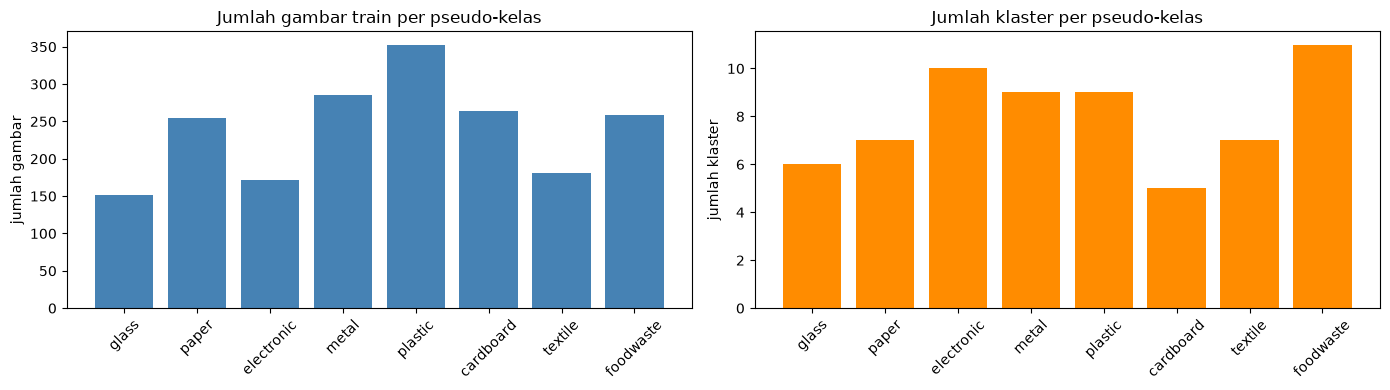

Rasio kelas terbesar/terkecil: 2.32 (terbesar: plastic=353, terkecil: glass=152).
Kelas dengan <=1 klaster (rapuh): []
Batas tafsir: distribusi ini adalah pseudo-label dari mapping model per klaster, bukan label ground truth.


In [27]:
# ----------------------------
# 7.4 Distribusi pseudo-label dan klaster per kelas
# ----------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(CLASSES, class_counts.values, color="steelblue")
axes[0].set_title("Jumlah gambar train per pseudo-kelas")
axes[0].set_ylabel("jumlah gambar"); axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(CLASSES, clusters_per_class.values, color="darkorange")
axes[1].set_title("Jumlah klaster per pseudo-kelas")
axes[1].set_ylabel("jumlah klaster"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

imb = class_counts.max() / max(int(class_counts.min()), 1)
print(f"Rasio kelas terbesar/terkecil: {imb:.2f} "
      f"(terbesar: {class_counts.idxmax()}={int(class_counts.max())}, "
      f"terkecil: {class_counts.idxmin()}={int(class_counts.min())}).")
print(f"Kelas dengan <=1 klaster (rapuh): {[c for c in CLASSES if clusters_per_class[c] <= 1]}")
print("Batas tafsir: distribusi ini adalah pseudo-label dari mapping model per klaster, bukan label ground truth.")

### 7.5 Self-consistency mapping (label-free)

Pertanyaan yang lebih tajam: untuk setiap gambar train, apakah ia lebih dekat ke centroid kelas hasil mapping-nya sendiri atau ke centroid kelas lain? Sel ini menghitung nearest-centroid secara out-of-fold, lalu membandingkannya dengan pseudo-label. Hasilnya bukan akurasi, tetapi indikator label noise: klaster dengan self-consistency rendah berarti isinya tidak homogen menurut fitur.

**Aturan:** mapping tidak diubah otomatis. Klaster dengan skor rendah hanya ditandai sebagai kandidat audit; mapping tidak diubah.

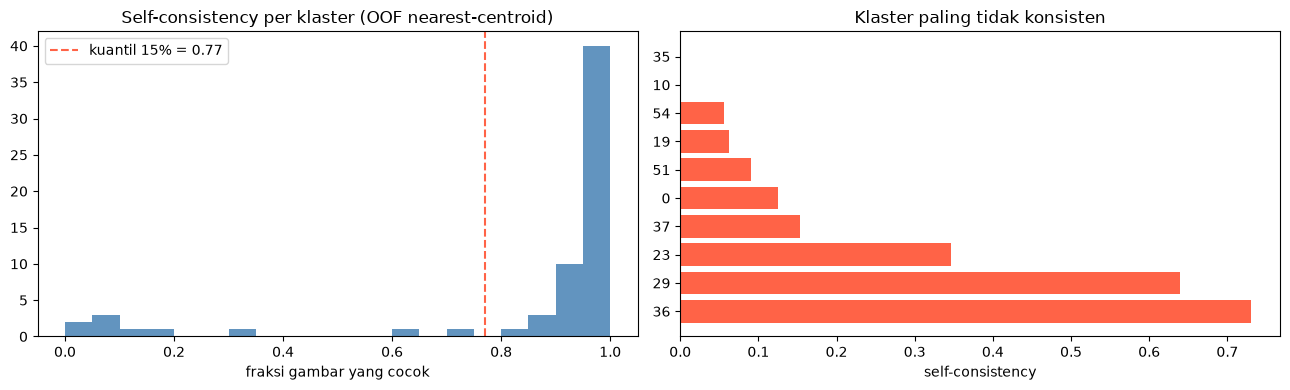

Self-consistency keseluruhan (OOF nearest-centroid vs pseudo-label): 0.9010
Klaster berisiko (kuantil 15% terendah): [35, 10, 54, 19, 51, 0, 37, 23, 29, 36]
Disimpan: artifacts_nb/cluster_risk_v1_1dc80bdb.csv
Batas tafsir: ini mengukur homogenitas pseudo-label menurut fitur, bukan akurasi kelas. Mapping tidak diubah otomatis.


In [28]:
# ----------------------------
# 7.5 Self-consistency mapping (label-free, out-of-fold)
# ----------------------------
from sklearn.preprocessing import normalize as _l2

y_local = train_clusters.pseudo_class.map(CLASS_TO_IDX).to_numpy()
nc_pred = np.full(len(train_df), -1, dtype=int)
fold_col = folds["fold_s0"].to_numpy()
for f in range(N_SPLITS):
    tr_mask = fold_col != f
    va_mask = ~tr_mask
    cent = np.vstack([X_train_comb[tr_mask & (y_local == c)].mean(axis=0) for c in range(len(CLASSES))])
    cent = _l2(cent)
    nc_pred[va_mask] = (X_train_comb[va_mask] @ cent.T).argmax(axis=1)
cons_img = (nc_pred == y_local).astype(float)

cluster_risk = (pd.DataFrame({"cluster": final_labels, "consistent": cons_img})
                .groupby("cluster").consistent.agg(["size", "mean"]).reset_index()
                .rename(columns={"size": "n", "mean": "self_consistency"})
                .sort_values("self_consistency"))
risk_path = ART_DIR / f"cluster_risk_{LABEL_VERSION}_{map_hash}.csv"
cluster_risk.to_csv(risk_path, index=False)

risk_thr = float(cluster_risk.self_consistency.quantile(0.15))
risky = cluster_risk[cluster_risk.self_consistency <= risk_thr]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(cluster_risk.self_consistency, bins=20, color="steelblue", alpha=0.85)
axes[0].axvline(risk_thr, color="tomato", linestyle="--", label=f"kuantil 15% = {risk_thr:.2f}")
axes[0].set_title("Self-consistency per klaster (OOF nearest-centroid)")
axes[0].set_xlabel("fraksi gambar yang cocok"); axes[0].legend()
axes[1].barh(risky.cluster.astype(str)[::-1], risky.self_consistency[::-1], color="tomato")
axes[1].set_title("Klaster paling tidak konsisten"); axes[1].set_xlabel("self-consistency")
plt.tight_layout(); plt.show()

mapping_self_consistency = float(cons_img.mean())
print(f"Self-consistency keseluruhan (OOF nearest-centroid vs pseudo-label): {mapping_self_consistency:.4f}")
print(f"Klaster berisiko (kuantil 15% terendah): {risky.cluster.astype(int).tolist()}")
print(f"Disimpan: {risk_path.relative_to(ROOT)}")
print("Batas tafsir: ini mengukur homogenitas pseudo-label menurut fitur, bukan akurasi kelas. Mapping tidak diubah otomatis.")

**Insight.** Sebagian besar klaster konsisten, tetapi beberapa klaster jelas berada di wilayah abu-abu: self-consistency-nya jauh di bawah rata-rata. Klaster-klaster ini adalah kandidat utama untuk dipecah menjadi sub-klaster dan ditandai untuk audit pada versi berikutnya. Untuk submission ini, mapping tetap dibekukan apa adanya; tidak ada label yang diubah berdasarkan skor ini, karena itu akan menjadi self-fulfilling prophecy.

**Keputusan:** tidak ada auto-relabel. Daftar klaster berisiko disimpan di `artifacts_nb/cluster_risk_v1_<hash>.csv` sebagai bahan review, bukan sebagai label baru.

## Bab 8 — Baseline linear probe & kNN dari pseudo-label klaster

**Tujuan:** melatih classifier dari pseudo-label hasil mapping klaster (bukan label manual per gambar), lalu mengukur stabilitas dan konsistensi prediksi tanpa mengklaim akurasi.

**Input:** fitur gabungan Bab 2, fold beku Bab 3, `pseudo_labels_v1_<hash>.csv` Bab 7.

**Output:** `artifacts_nb/pred_baseline_v1_<hash>.npz`, `artifacts_nb/baseline_metrics_v1_<hash>.json`.

**Kriteria lolos (Gate 8):**
- Prediksi OOF dan test tersedia untuk ketiga seed, semua finite, dan jumlah probabilitas ≈ 1.
- Metrik yang dilaporkan: kesepakatan dengan pseudo-label (bukan akurasi), kesepakatan antar seed, entropy, max share, konsistensi 10-NN, dan 3 pasangan duplikat.
- Tidak ada pemilihan model berdasarkan public LB dan tidak ada klaim akurasi.

In [29]:
# ============================================================
# BAB 8 - BASELINE LINEAR PROBE & kNN
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

y_idx = train_clusters.pseudo_class.map(CLASS_TO_IDX).to_numpy()
require(len(y_idx) == len(train_df), "Panjang pseudo-label tidak sama dengan train.")
# map_hash dihitung di Bab 7.3b (termasuk hash override sub-cluster bila ada).

def expand_proba(proba, classes):
    out = np.zeros((proba.shape[0], len(CLASSES)), dtype=float)
    for j, c in enumerate(classes):
        out[:, int(c)] = proba[:, j]
    return out

def cv_logreg(Xtr_all, ytr_all, folds_df, Xtest, extra_X=None, extra_y=None, C=1.0):
    oof = np.zeros((len(CV_SEEDS), len(ytr_all), len(CLASSES)), dtype=float)
    test = np.zeros((len(CV_SEEDS), len(Xtest), len(CLASSES)), dtype=float)
    for si, s in enumerate(CV_SEEDS):
        for f in range(N_SPLITS):
            va = folds_df[f"fold_s{s}"].to_numpy() == f
            tr = ~va
            Xt, yt = Xtr_all[tr], ytr_all[tr]
            if extra_X is not None:
                Xt = np.vstack([Xt, extra_X])
                yt = np.concatenate([yt, extra_y])
            clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED)
            clf.fit(Xt, yt)
            oof[si, va] = expand_proba(clf.predict_proba(Xtr_all[va]), clf.classes_)
            test[si] += expand_proba(clf.predict_proba(Xtest), clf.classes_) / N_SPLITS
    return oof, test

def cv_knn(Xtr_all, ytr_all, folds_df, Xtest, k=KNN_K):
    oof = np.zeros((len(CV_SEEDS), len(ytr_all), len(CLASSES)), dtype=float)
    test = np.zeros((len(CV_SEEDS), len(Xtest), len(CLASSES)), dtype=float)
    for si, s in enumerate(CV_SEEDS):
        for f in range(N_SPLITS):
            va = folds_df[f"fold_s{s}"].to_numpy() == f
            tr = ~va
            clf = KNeighborsClassifier(n_neighbors=k, metric="cosine", weights="distance")
            clf.fit(Xtr_all[tr], ytr_all[tr])
            oof[si, va] = expand_proba(clf.predict_proba(Xtr_all[va]), clf.classes_)
            test[si] += expand_proba(clf.predict_proba(Xtest), clf.classes_) / N_SPLITS
    return oof, test

pred_path = ART_DIR / f"pred_baseline_{LABEL_VERSION}_{map_hash}.npz"
if pred_path.exists():
    with np.load(pred_path) as z:
        oof_linear = np.asarray(z["oof_linear"]); test_linear = np.asarray(z["test_linear"])
        oof_knn = np.asarray(z["oof_knn"]); test_knn = np.asarray(z["test_knn"])
        y_saved = np.asarray(z["y_idx"])
    require(np.array_equal(y_saved, y_idx), "Cache prediksi memakai pseudo-label berbeda. Hapus/naikkan versi.")
    print(f"Prediksi baseline dimuat: {pred_path.relative_to(ROOT)}")
else:
    print("Melatih baseline linear probe (5 fold x 3 seed) ...")
    t0 = time.time()
    oof_linear, test_linear = cv_logreg(X_train_comb, y_idx, folds, X_test_comb)
    print(f"  linear selesai ({time.time()-t0:.1f}s); melatih kNN ...")
    oof_knn, test_knn = cv_knn(X_train_comb, y_idx, folds, X_test_comb)
    np.savez_compressed(pred_path, oof_linear=oof_linear, test_linear=test_linear,
                        oof_knn=oof_knn, test_knn=test_knn, y_idx=y_idx,
                        seeds=np.array(CV_SEEDS))
    print(f"Prediksi baseline disimpan: {pred_path.relative_to(ROOT)}")

Prediksi baseline dimuat: artifacts_nb/pred_baseline_v1_1dc80bdb.npz


In [30]:
# ----------------------------
# 8.1 Metrik proksi (bukan akurasi)
# ----------------------------
def pairwise_agreement(pred_list):
    vals = []
    for i in range(len(pred_list)):
        for j in range(i + 1, len(pred_list)):
            vals.append(float((pred_list[i] == pred_list[j]).mean()))
    return float(np.mean(vals)) if vals else np.nan

def mean_entropy(proba):
    return float((-(proba * np.log(proba + 1e-12)).sum(axis=1)).mean())

def max_class_share(pred):
    return float(np.bincount(pred, minlength=len(CLASSES)).max() / len(pred))

def duplicate_pair_metrics(pred_train, pred_test, pairs_df, y_ref):
    tr_pos = {f: i for i, f in enumerate(train_df.filename)}
    te_pos = {f: i for i, f in enumerate(test_df.filename)}
    model_agree, pseudo_agree = [], []
    for _, r in pairs_df.iterrows():
        ti, ei = tr_pos[r.train_filename], te_pos[r.test_filename]
        model_agree.append(bool(pred_train[ti] == pred_test[ei]))
        pseudo_agree.append(bool(pred_test[ei] == y_ref[ti]))
    return float(np.mean(model_agree)), float(np.mean(pseudo_agree))

nbr_train = knn_indices(X_train_comb, k=10)
nn_test = NearestNeighbors(n_neighbors=10, metric="cosine").fit(X_train_comb)
_, nbr_test = nn_test.kneighbors(X_test_comb)

def metric_block(oof, test_probs, y_ref, pairs_df):
    pred_oof = [p.argmax(1) for p in oof]
    pred_test = [p.argmax(1) for p in test_probs]
    pred_oof_mean = oof.mean(0).argmax(1)
    pred_test_mean = test_probs.mean(0).argmax(1)
    dup_model, dup_pseudo = duplicate_pair_metrics(pred_oof_mean, pred_test_mean, pairs_df, y_ref)
    return {
        "pseudo_agree_oof": float(np.mean([(p == y_ref).mean() for p in pred_oof])),
        "seed_agree_oof": pairwise_agreement(pred_oof),
        "seed_agree_test": pairwise_agreement(pred_test),
        "entropy_test": float(np.mean([mean_entropy(p) for p in test_probs])),
        "max_share_test": float(np.mean([max_class_share(p) for p in pred_test])),
        "dup_model_agree": dup_model,
        "dup_pseudo_agree": dup_pseudo,
        "knn_cons_train": float((pred_oof_mean[nbr_train] == pred_oof_mean[:, None]).mean()),
        "knn_cons_test": float((y_ref[nbr_test] == pred_test_mean[:, None]).mean()),
        "class_dist_test": (np.bincount(pred_test_mean, minlength=len(CLASSES)) / len(pred_test_mean)).tolist(),
    }

met_linear = metric_block(oof_linear, test_linear, y_idx, pairs)
met_knn = metric_block(oof_knn, test_knn, y_idx, pairs)

metric_rows = []
for name, m in [("linear", met_linear), ("knn", met_knn)]:
    metric_rows.append({
        "model": name,
        "pseudo_agree_oof": m["pseudo_agree_oof"],
        "seed_agree_oof": m["seed_agree_oof"],
        "seed_agree_test": m["seed_agree_test"],
        "entropy_test": m["entropy_test"],
        "max_share_test": m["max_share_test"],
        "dup_model_agree": m["dup_model_agree"],
        "dup_pseudo_agree": m["dup_pseudo_agree"],
        "knn_cons_train": m["knn_cons_train"],
        "knn_cons_test": m["knn_cons_test"],
    })
baseline_table = pd.DataFrame(metric_rows)
metrics_path = ART_DIR / f"baseline_metrics_{LABEL_VERSION}_{map_hash}.json"
save_json({"created_at": RUN_TS, "linear": met_linear, "knn": met_knn,
           "note": "pseudo_agree is agreement with cluster-derived pseudo-labels, not accuracy."}, metrics_path)

print("Baseline (metrik proksi; pseudo_agree BUKAN akurasi):")
print(baseline_table.round(4).to_string(index=False))
print("\nDistribusi prediksi test (linear, rata-rata seed):")
print(pd.Series(met_linear["class_dist_test"], index=CLASSES).round(3).to_string())
print(f"\nBaseline utama: linear probe. kNN dipakai sebagai pembanding dan untuk smoothing Bab 9.")
print("Pemilihan ini BUKAN klaim akurasi terbaik; tidak ada label untuk membuktikannya.")

Baseline (metrik proksi; pseudo_agree BUKAN akurasi):
 model  pseudo_agree_oof  seed_agree_oof  seed_agree_test  entropy_test  max_share_test  dup_model_agree  dup_pseudo_agree  knn_cons_train  knn_cons_test
linear            0.9648          0.9903              1.0        0.9046          0.2125              1.0            0.6667          0.9429         0.9271
   knn            0.9681          0.9910              1.0        0.1813          0.2333              1.0            1.0000          0.9553         0.9525

Distribusi prediksi test (linear, rata-rata seed):
glass         0.090
paper         0.112
electronic    0.100
metal         0.131
plastic       0.212
cardboard     0.129
textile       0.075
foodwaste     0.150

Baseline utama: linear probe. kNN dipakai sebagai pembanding dan untuk smoothing Bab 9.
Pemilihan ini BUKAN klaim akurasi terbaik; tidak ada label untuk membuktikannya.


In [31]:
# ----------------------------
# 8.2 Gate 8
# ----------------------------
finite_ok = all(np.isfinite(a).all() for a in (oof_linear, test_linear, oof_knn, test_knn))
sum_ok = all(np.allclose(a.sum(axis=2), 1.0, atol=1e-5) for a in (oof_linear, test_linear, oof_knn, test_knn))
shape_ok = (oof_linear.shape == (len(CV_SEEDS), len(train_df), len(CLASSES)) and
            test_linear.shape == (len(CV_SEEDS), len(test_df), len(CLASSES)) and
            oof_knn.shape == oof_linear.shape and test_knn.shape == test_linear.shape)

print("RINGKASAN BAB 8 - BASELINE")
print(f"- Linear: pseudo_agree={met_linear['pseudo_agree_oof']:.3f} | seed_agree_test={met_linear['seed_agree_test']:.3f} | "
      f"dup_model={met_linear['dup_model_agree']:.3f} | max_share={met_linear['max_share_test']:.3f}.")
print(f"- kNN   : pseudo_agree={met_knn['pseudo_agree_oof']:.3f} | seed_agree_test={met_knn['seed_agree_test']:.3f} | "
      f"dup_model={met_knn['dup_model_agree']:.3f} | max_share={met_knn['max_share_test']:.3f}.")
print(f"- Finite={finite_ok} | sum_to_1={sum_ok} | shape={shape_ok}.")
require(finite_ok and sum_ok and shape_ok, "Gate 8 gagal: prediksi baseline tidak valid.")
print("- Gate 8: LULUS - prediksi lengkap dan valid secara numerik.")
print("Batas tafsir: semua angka di atas adalah proksi. Tidak ada angka akurasi di notebook ini.")

RINGKASAN BAB 8 - BASELINE
- Linear: pseudo_agree=0.965 | seed_agree_test=1.000 | dup_model=1.000 | max_share=0.212.
- kNN   : pseudo_agree=0.968 | seed_agree_test=1.000 | dup_model=1.000 | max_share=0.233.
- Finite=True | sum_to_1=True | shape=True.
- Gate 8: LULUS - prediksi lengkap dan valid secara numerik.
Batas tafsir: semua angka di atas adalah proksi. Tidak ada angka akurasi di notebook ini.


### 8.3 Confusion terhadap pseudo-label dan label-noise risk

Model linear probe cocok dengan pseudo-label, tetapi kita perlu melihat pola kesalahannya. Confusion matrix di bawah membandingkan prediksi OOF dengan pseudo-label klaster, **bukan** dengan ground truth. Ini berguna untuk menemukan kelas yang paling sering tertukar dan untuk menilai apakah error tersebar atau terkonsentrasi.

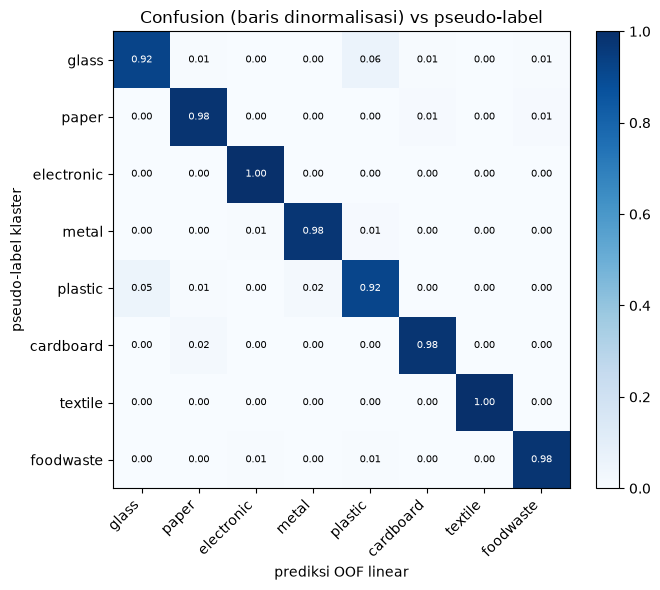

Agreement OOF vs pseudo-label per kelas:
glass         0.921
paper         0.984
electronic    1.000
metal         0.975
plastic       0.918
cardboard     0.977
textile       1.000
foodwaste     0.977
Agreement rata-rata kelas: 0.9691 | mikro: 0.9667
Batas tafsir: ini kecocokan dengan pseudo-label, bukan akurasi. Nilai tinggi bisa berarti model meniru noise label.


In [32]:
# ----------------------------
# 8.3 Confusion terhadap pseudo-label (bukan ground truth)
# ----------------------------
from sklearn.metrics import confusion_matrix

oof_pred_mean = oof_linear.mean(0).argmax(1)
cm = confusion_matrix(y_idx, oof_pred_mean, labels=list(range(len(CLASSES))))
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
ax.set_xlabel("prediksi OOF linear"); ax.set_ylabel("pseudo-label klaster")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=7)
ax.set_title("Confusion (baris dinormalisasi) vs pseudo-label")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

per_class_agree = pd.Series(cm.diagonal() / np.clip(cm.sum(1), 1, None), index=CLASSES)
print("Agreement OOF vs pseudo-label per kelas:")
print(per_class_agree.round(3).to_string())
print(f"Agreement rata-rata kelas: {per_class_agree.mean():.4f} | mikro: {cm.diagonal().sum()/cm.sum():.4f}")
print("Batas tafsir: ini kecocokan dengan pseudo-label, bukan akurasi. Nilai tinggi bisa berarti model meniru noise label.")

**Insight.** Agreement linear probe terhadap pseudo-label tinggi, tetapi tidak merata. Kelas plastic paling sering meleset; metal dan foodwaste hampir sempurna. Error tidak terkonsentrasi pada satu pasangan kelas, melainkan tersebar. Pola ini lebih konsisten dengan noise label dan batas kelas yang kabur daripada dengan satu boundary model yang salah.

**Keputusan:** tidak ada perubahan label berdasarkan confusion ini. Metrik ini hanya dipakai untuk memahami risiko, bukan untuk memilih model berdasarkan pseudo-label.

## Bab 9 — Self-training, kNN smoothing, dan konsistensi flip/crop

**Tujuan:** mencoba perbaikan tanpa fine-tuning: self-training dari test berkonfidensi tinggi, lalu kNN smoothing. Perubahan hanya diterima jika metrik proksi membaik konsisten di semua seed.

**Input:** prediksi baseline Bab 8, fitur test varian identity/flip/crop (diekstrak sekali dan di-cache), pseudo-label Bab 7.

**Output:** `artifacts_nb/features_test_variants_v1.npz`, `artifacts_nb/model_gate_v1_<hash>.json`, `artifacts_nb/pred_selected_v1_<hash>.npz`.

**Kriteria lolos (Gate 9):**
- Self-training diterima hanya jika, untuk **setiap seed**, variant agreement tidak turun dan rata-rata naik ≥ 0,002; seed agreement, duplicate consistency, dan pseudo-label OOF tidak turun; distribusi tidak kolaps.
- kNN smoothing diterima hanya jika seed agreement dan duplicate consistency tidak turun serta distribusi tidak kolaps.
- Jika gate gagal, baseline dipertahankan dan alasannya dicetak.
- Tidak ada klaim akurasi; variant agreement bisa naik hanya karena prediksi menjadi lebih seragam.

In [33]:
# ============================================================
# BAB 9 - SELF-TRAINING + kNN SMOOTHING + KONSISTENSI FLIP/CROP
# ============================================================
var_path = ART_DIR / f"features_test_variants_{STABILITY_VERSION}.npz"

@torch.inference_mode()
def embed_identity_flip(model, transform, paths, batch_size):
    out_id, out_fl, i, bs = [], [], 0, int(batch_size)
    t0 = time.time()
    while i < len(paths):
        chunk = paths[i:i + bs]
        x = torch.stack([transform(load_image(p)) for p in chunk]).to(DEVICE)
        try:
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
                f_id = model(x)
                f_fl = model(torch.flip(x, dims=[3]))
            out_id.append(F.normalize(f_id.float(), dim=-1).cpu().numpy())
            out_fl.append(F.normalize(f_fl.float(), dim=-1).cpu().numpy())
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and bs > 1:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); continue
            raise
        i += len(chunk)
        if i % max(bs * 10, 10) == 0 or i == len(paths):
            print(f"  identity+flip {i}/{len(paths)} | {time.time()-t0:.0f}s")
    return np.concatenate(out_id, axis=0), np.concatenate(out_fl, axis=0)

@torch.inference_mode()
def embed_variant(model, transform, paths, batch_size):
    out, i, bs = [], 0, int(batch_size)
    t0 = time.time()
    while i < len(paths):
        chunk = paths[i:i + bs]
        x = torch.stack([transform(load_image(p)) for p in chunk]).to(DEVICE)
        try:
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda")):
                f = model(x)
            out.append(F.normalize(f.float(), dim=-1).cpu().numpy())
        except RuntimeError as e:
            if "out of memory" in str(e).lower() and bs > 1:
                torch.cuda.empty_cache(); bs = max(1, bs // 2); continue
            raise
        i += len(chunk)
        if i % max(bs * 10, 10) == 0 or i == len(paths):
            print(f"  crop {i}/{len(paths)} | {time.time()-t0:.0f}s")
    return np.concatenate(out, axis=0)

if var_path.exists():
    with np.load(var_path) as z:
        var = {k: np.asarray(z[k], dtype=np.float32) for k in z.files}
    print(f"Fitur varian test dimuat: {var_path.relative_to(ROOT)}")
else:
    print("Ekstraksi fitur test varian identity/flip/crop (sekali saja) ...")
    t0 = time.time()
    per_model = {}
    for name, spec in MODELS.items():
        extra = {"img_size": spec["img_size"]} if spec["img_size"] else {}
        model = timm.create_model(spec["model_name"], pretrained=True, num_classes=0, **extra).to(DEVICE).eval()
        cfg = timm.data.resolve_data_config({}, model=model)
        if spec["img_size"]:
            cfg = dict(cfg)
            cfg["input_size"] = (3, spec["img_size"], spec["img_size"])
            cfg["crop_pct"] = 1.0
        tf_id = timm.data.create_transform(**cfg, is_training=False)
        cfg_crop = dict(cfg); cfg_crop["crop_pct"] = 0.85
        tf_crop = timm.data.create_transform(**cfg_crop, is_training=False)
        id_arr, fl_arr = embed_identity_flip(model, tf_id, test_df.path.tolist(), BATCH_SIZE)
        cr_arr = embed_variant(model, tf_crop, test_df.path.tolist(), BATCH_SIZE)
        per_model[name] = {"identity": id_arr, "flip": fl_arr, "crop": cr_arr}
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print(f"  {name} selesai ({time.time()-t0:.0f}s)")
    var = {v: np.hstack([per_model[n][v] for n in MODELS]) / np.sqrt(len(MODELS))
           for v in ("identity", "flip", "crop")}
    np.savez_compressed(var_path, **var)
    print(f"Fitur varian test disimpan: {var_path.relative_to(ROOT)} ({time.time()-t0:.0f}s)")

require(all(v.shape == (len(test_df), X_test_comb.shape[1]) for v in var.values()),
        "Shape fitur varian test tidak cocok dengan fitur gabungan.")
require(all(np.isfinite(v).all() for v in var.values()), "Ada NaN/Inf di fitur varian test.")
print(f"Varian test: {list(var.keys())} | shape={var['identity'].shape}")

Fitur varian test dimuat: artifacts_nb/features_test_variants_v1.npz
Varian test: ['identity', 'flip', 'crop'] | shape=(480, 2560)


In [34]:
# ----------------------------
# 9.1 Baseline + self-training (2 iterasi) dengan prediksi varian
# ----------------------------
def cv_logreg_variants(Xtr_all, ytr_all, folds_df, Xte_dict, extra_X=None, extra_y=None, C=1.0):
    oof = np.zeros((len(CV_SEEDS), len(ytr_all), len(CLASSES)), dtype=float)
    test = {v: np.zeros((len(CV_SEEDS), Xte_dict[v].shape[0], len(CLASSES)), dtype=float) for v in Xte_dict}
    for si, s in enumerate(CV_SEEDS):
        for f in range(N_SPLITS):
            va = folds_df[f"fold_s{s}"].to_numpy() == f
            tr = ~va
            Xt, yt = Xtr_all[tr], ytr_all[tr]
            if extra_X is not None:
                Xt = np.vstack([Xt, extra_X]); yt = np.concatenate([yt, extra_y])
            clf = LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED)
            clf.fit(Xt, yt)
            oof[si, va] = expand_proba(clf.predict_proba(Xtr_all[va]), clf.classes_)
            for v in Xte_dict:
                test[v][si] += expand_proba(clf.predict_proba(Xte_dict[v]), clf.classes_) / N_SPLITS
    return oof, test

def variant_metrics(oof, var_probs, y_ref, pairs_df):
    m = metric_block(oof, var_probs["identity"], y_ref, pairs_df)
    per_seed = []
    for s in range(len(CV_SEEDS)):
        P = [var_probs[v][s].argmax(1) for v in ("identity", "flip", "crop")]
        a = ((P[0] == P[1]).astype(float) + (P[1] == P[2]).astype(float) + (P[0] == P[2]).astype(float)) / 3.0
        per_seed.append(float(a.mean()))
    m["variant_agree_mean"] = float(np.mean(per_seed))
    m["variant_agree_per_seed"] = per_seed
    return m

def high_conf_mask(var_probs, conf_thr=SELF_TRAIN_CONF):
    P = var_probs["identity"]
    mean_p = P.mean(0)
    pred = mean_p.argmax(1)
    conf = mean_p.max(1)
    p0, p1, p2 = [P[s].argmax(1) for s in range(len(CV_SEEDS))]
    agree = (p0 == p1) & (p1 == p2)
    return (conf >= conf_thr) & agree, pred

print("Baseline: linear probe pada fitur gabungan, prediksi 3 varian ...")
t0 = time.time()
oof_base, var_base = cv_logreg_variants(X_train_comb, y_idx, folds, var)
met_base = variant_metrics(oof_base, var_base, y_idx, pairs)
print(f"  baseline selesai ({time.time()-t0:.1f}s)")

mask1, pred1 = high_conf_mask(var_base)
print(f"Self-training iterasi 1: {int(mask1.sum())}/{len(test_df)} test berkonfidensi >= {SELF_TRAIN_CONF:.2f} dan disepakati 3 seed.")
oof_it1, var_it1 = cv_logreg_variants(X_train_comb, y_idx, folds, var,
                                      extra_X=X_test_comb[mask1], extra_y=pred1[mask1])
met_it1 = variant_metrics(oof_it1, var_it1, y_idx, pairs)

mask2, pred2 = high_conf_mask(var_it1)
print(f"Self-training iterasi 2: {int(mask2.sum())}/{len(test_df)} test dipakai.")
oof_it2, var_it2 = cv_logreg_variants(X_train_comb, y_idx, folds, var,
                                      extra_X=X_test_comb[mask2], extra_y=pred2[mask2])
met_it2 = variant_metrics(oof_it2, var_it2, y_idx, pairs)

Baseline: linear probe pada fitur gabungan, prediksi 3 varian ...


  baseline selesai (1.8s)
Self-training iterasi 1: 60/480 test berkonfidensi >= 0.95 dan disepakati 3 seed.


Self-training iterasi 2: 62/480 test dipakai.


In [35]:
# ----------------------------
# 9.2 Gate penerimaan self-training
# ----------------------------
def gate_checks(base, cand):
    return {
        "variant_mean_up": bool(cand["variant_agree_mean"] >= base["variant_agree_mean"] + 0.002),
        "variant_all_seeds_no_drop": bool(all(c >= b - 1e-9 for b, c in zip(base["variant_agree_per_seed"], cand["variant_agree_per_seed"]))),
        "seed_agree_no_drop": bool(cand["seed_agree_test"] >= base["seed_agree_test"] - 1e-9),
        "dup_model_no_drop": bool(cand["dup_model_agree"] >= base["dup_model_agree"] - 1e-9),
        "dup_pseudo_no_drop": bool(cand["dup_pseudo_agree"] >= base["dup_pseudo_agree"] - 1e-9),
        "pseudo_oof_no_drop": bool(cand["pseudo_agree_oof"] >= base["pseudo_agree_oof"] - 0.005),
        "not_collapsed": bool(cand["max_share_test"] <= 0.60 and cand["entropy_test"] >= 0.50),
    }

candidates = [("self_train_it1", met_it1, oof_it1, var_it1),
              ("self_train_it2", met_it2, oof_it2, var_it2)]
accepted = []
for name, m, oof, vp in candidates:
    checks = gate_checks(met_base, m)
    print(f"\n{name}: " + " | ".join(f"{k}={v}" for k, v in checks.items()))
    if all(checks.values()):
        accepted.append((name, m, oof, vp, checks))

if accepted:
    accepted.sort(key=lambda x: x[1]["variant_agree_mean"], reverse=True)
    selected_name, met_sel, oof_sel, var_sel, checks_sel = accepted[0]
    print(f"\nSelf-training DITERIMA: {selected_name}")
else:
    selected_name, met_sel, oof_sel, var_sel, checks_sel = "baseline", met_base, oof_base, var_base, {}
    print("\nSelf-training DITOLAK: tidak ada kandidat yang lolos semua syarat. Baseline dipertahankan.")


self_train_it1: variant_mean_up=False | variant_all_seeds_no_drop=False | seed_agree_no_drop=True | dup_model_no_drop=True | dup_pseudo_no_drop=True | pseudo_oof_no_drop=True | not_collapsed=True

self_train_it2: variant_mean_up=False | variant_all_seeds_no_drop=False | seed_agree_no_drop=True | dup_model_no_drop=True | dup_pseudo_no_drop=True | pseudo_oof_no_drop=True | not_collapsed=True

Self-training DITOLAK: tidak ada kandidat yang lolos semua syarat. Baseline dipertahankan.


In [36]:
# ----------------------------
# 9.3 kNN smoothing (alpha tetap, bukan tuning LB)
# ----------------------------
knn_smooth = KNeighborsClassifier(n_neighbors=KNN_K, metric="cosine", weights="distance")
knn_smooth.fit(X_train_comb, y_idx)
P_knn_test = expand_proba(knn_smooth.predict_proba(X_test_comb), knn_smooth.classes_)

var_smooth = {v: (1.0 - SMOOTH_ALPHA) * var_sel[v] + SMOOTH_ALPHA * P_knn_test[None, :, :]
              for v in var_sel}
met_smooth = variant_metrics(oof_sel, var_smooth, y_idx, pairs)

smooth_checks = {
    "seed_agree_no_drop": bool(met_smooth["seed_agree_test"] >= met_sel["seed_agree_test"] - 1e-9),
    "dup_model_no_drop": bool(met_smooth["dup_model_agree"] >= met_sel["dup_model_agree"] - 1e-9),
    "dup_pseudo_no_drop": bool(met_smooth["dup_pseudo_agree"] >= met_sel["dup_pseudo_agree"] - 1e-9),
    "not_collapsed": bool(met_smooth["max_share_test"] <= 0.60 and met_smooth["entropy_test"] >= 0.50),
}
print("kNN smoothing checks: " + " | ".join(f"{k}={v}" for k, v in smooth_checks.items()))
if all(smooth_checks.values()):
    selected_name = selected_name + "+knn_smooth"
    met_final = met_smooth
    var_final = var_smooth
    print(f"kNN smoothing DITERIMA -> {selected_name}")
else:
    met_final = met_sel
    var_final = var_sel
    print("kNN smoothing DITOLAK: metrik proksi tidak membaik. Model sebelumnya dipertahankan.")

rows = [
    ("baseline", met_base),
    ("self_train_it1", met_it1),
    ("self_train_it2", met_it2),
    ("selected_before_smooth", met_sel),
    ("selected_final", met_final),
]
comp = pd.DataFrame([{
    "method": name,
    "variant_agree": m["variant_agree_mean"],
    "seed_agree_test": m["seed_agree_test"],
    "dup_model": m["dup_model_agree"],
    "dup_pseudo": m["dup_pseudo_agree"],
    "pseudo_oof": m["pseudo_agree_oof"],
    "entropy": m["entropy_test"],
    "max_share": m["max_share_test"],
    "knn_cons_test": m["knn_cons_test"],
} for name, m in rows])
print("\nPerbandingan proksi (BUKAN akurasi):")
print(comp.round(4).to_string(index=False))
print("\nDistribusi prediksi test final:")
print(pd.Series(met_final["class_dist_test"], index=CLASSES).round(3).to_string())

kNN smoothing checks: seed_agree_no_drop=True | dup_model_no_drop=False | dup_pseudo_no_drop=True | not_collapsed=True
kNN smoothing DITOLAK: metrik proksi tidak membaik. Model sebelumnya dipertahankan.

Perbandingan proksi (BUKAN akurasi):
                method  variant_agree  seed_agree_test  dup_model  dup_pseudo  pseudo_oof  entropy  max_share  knn_cons_test
              baseline         0.9917           0.9986        1.0      0.6667      0.9648   0.9060     0.2132         0.9288
        self_train_it1         0.9917           1.0000        1.0      0.6667      0.9655   0.8979     0.2146         0.9275
        self_train_it2         0.9917           1.0000        1.0      0.6667      0.9653   0.8977     0.2146         0.9275
selected_before_smooth         0.9917           0.9986        1.0      0.6667      0.9648   0.9060     0.2132         0.9288
        selected_final         0.9917           0.9986        1.0      0.6667      0.9648   0.9060     0.2132         0.9288

Distribu

In [37]:
# ----------------------------
# 9.4 Simpan keputusan + gate 9
# ----------------------------
final_test_probs = var_final["identity"]
finite_ok = bool(np.isfinite(final_test_probs).all())
sum_ok = bool(np.allclose(final_test_probs.sum(axis=2), 1.0, atol=1e-5))
shape_ok = final_test_probs.shape == (len(CV_SEEDS), len(test_df), len(CLASSES))

gate9 = {
    "created_at": RUN_TS,
    "mapping_version": LABEL_VERSION,
    "mapping_source": mapping_source,
    "mapping_sha256": sha256_file(map_path),
    "selected_method": selected_name,
    "baseline": met_base,
    "self_train_it1": met_it1,
    "self_train_it2": met_it2,
    "selected_before_smooth": met_sel,
    "selected_final": met_final,
    "self_train_checks": checks_sel,
    "smoothing_checks": smooth_checks,
    "self_train_accepted": bool(accepted),
    "smoothing_accepted": bool(all(smooth_checks.values())),
    "final_finite": finite_ok,
    "final_sum_to_1": sum_ok,
    "note": "All metrics are label-free proxies. No accuracy claim; no public-LB tuning.",
}
gate_path = ART_DIR / f"model_gate_{LABEL_VERSION}_{map_hash}.json"
save_json(gate9, gate_path)

selected_path = ART_DIR / f"pred_selected_{LABEL_VERSION}_{map_hash}.npz"
np.savez_compressed(selected_path,
                    test_identity=final_test_probs,
                    test_flip=var_final["flip"],
                    test_crop=var_final["crop"],
                    test_probs=final_test_probs,
                    seeds=np.array(CV_SEEDS),
                    method=np.array([selected_name]))

print("RINGKASAN BAB 9 - SELF-TRAINING & SMOOTHING")
print(f"- Metode dipilih: {selected_name}")
print(f"- Variant agreement: baseline={met_base['variant_agree_mean']:.4f} | final={met_final['variant_agree_mean']:.4f}")
print(f"- Seed agreement test: baseline={met_base['seed_agree_test']:.4f} | final={met_final['seed_agree_test']:.4f}")
print(f"- Duplicate model agree: baseline={met_base['dup_model_agree']:.3f} | final={met_final['dup_model_agree']:.3f}")
print(f"- Max class share: baseline={met_base['max_share_test']:.3f} | final={met_final['max_share_test']:.3f}")
print(f"- Finite={finite_ok} | sum_to_1={sum_ok} | shape={shape_ok}")
require(finite_ok and sum_ok and shape_ok, "Gate 9 gagal: prediksi final tidak valid.")
print(f"- Gate 9: LULUS - keputusan diterima/ditolak tercatat; metrik proksi dilaporkan.")
print(f"- Keputusan: {gate_path.relative_to(ROOT)} | Prediksi: {selected_path.relative_to(ROOT)}")
print("Batas tafsir: variant agreement dapat naik karena prediksi menyeragamkan kelas. "
      "Tidak ada label yang membuktikan akurasi; submission Bab 10 hanya konfirmasi, bukan bukti benar.")

RINGKASAN BAB 9 - SELF-TRAINING & SMOOTHING
- Metode dipilih: baseline
- Variant agreement: baseline=0.9917 | final=0.9917
- Seed agreement test: baseline=0.9986 | final=0.9986
- Duplicate model agree: baseline=1.000 | final=1.000
- Max class share: baseline=0.213 | final=0.213
- Finite=True | sum_to_1=True | shape=True
- Gate 9: LULUS - keputusan diterima/ditolak tercatat; metrik proksi dilaporkan.
- Keputusan: artifacts_nb/model_gate_v1_1dc80bdb.json | Prediksi: artifacts_nb/pred_selected_v1_1dc80bdb.npz
Batas tafsir: variant agreement dapat naik karena prediksi menyeragamkan kelas. Tidak ada label yang membuktikan akurasi; submission Bab 10 hanya konfirmasi, bukan bukti benar.


### 9.5 Sensitivitas ambang self-training (analisis, bukan tuning)

Ambang 0,95 dikunci sebelum melihat LB. Untuk memahami konsekuensinya, sel ini menghitung berapa banyak gambar test yang akan dipakai pada beberapa ambang, tanpa melatih ulang model. Tujuannya transparansi: ambang rendah memasukkan lebih banyak test, tetapi juga lebih banyak noise.

 threshold  n_test_dipakai  share
      0.50             412  0.858
      0.70             308  0.642
      0.80             255  0.531
      0.90             129  0.269
      0.95              60  0.125
      0.99               0  0.000


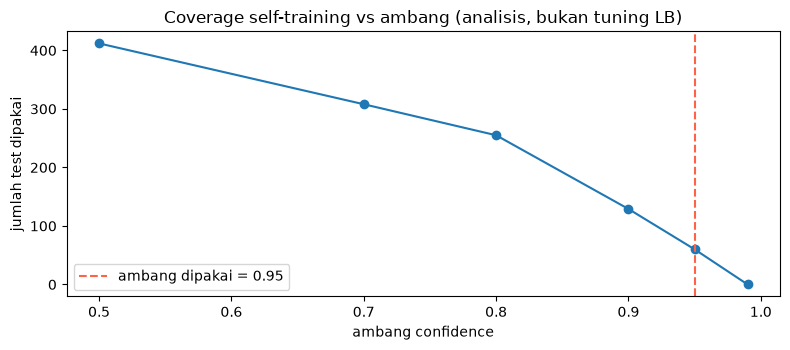

Ambang 0.95 (dipakai) mencakup 60/480 gambar test.
Batas tafsir: ambang lebih rendah menambah data test tetapi juga menambah noise; keputusan tetap pada ambang yang dikunci sebelum melihat LB.


In [38]:
# ----------------------------
# 9.5 Sensitivitas ambang self-training (analisis, bukan tuning)
# ----------------------------
mean_conf = final_test_probs.mean(0).max(axis=1)
thresholds = [0.50, 0.70, 0.80, 0.90, 0.95, 0.99]
thr_rows = []
for thr in thresholds:
    used = mean_conf >= thr
    thr_rows.append({"threshold": thr, "n_test_dipakai": int(used.sum()), "share": float(used.mean())})
thr_table = pd.DataFrame(thr_rows)
print(thr_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(thr_table.threshold, thr_table.n_test_dipakai, marker="o")
ax.axvline(SELF_TRAIN_CONF, color="tomato", linestyle="--", label=f"ambang dipakai = {SELF_TRAIN_CONF}")
ax.set_xlabel("ambang confidence"); ax.set_ylabel("jumlah test dipakai")
ax.set_title("Coverage self-training vs ambang (analisis, bukan tuning LB)")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Ambang {SELF_TRAIN_CONF} (dipakai) mencakup {int((mean_conf >= SELF_TRAIN_CONF).sum())}/{len(test_df)} gambar test.")
print("Batas tafsir: ambang lebih rendah menambah data test tetapi juga menambah noise; keputusan tetap pada ambang yang dikunci sebelum melihat LB.")

## Bab 10 — Submission final

**Tujuan:** membekukan prediksi Bab 9 menjadi file CSV yang valid, lalu memeriksa format dan reproduktibilitasnya.



In [39]:
# ============================================================
# BAB 10 - SUBMISSION FINAL
# ============================================================
import shutil

mean_test_probs = final_test_probs.mean(0)
pred_test_idx = mean_test_probs.argmax(axis=1)
pred_test_class = [CLASSES[i] for i in pred_test_idx]

submission = pd.DataFrame({
    "image_id": test_df.image_id.astype(str).values,
    "waste_category": pred_test_class,
})

require(len(submission) == 480, f"Submission harus 480 baris, ditemukan {len(submission)}.")
require(submission.image_id.is_unique, "image_id submission tidak unik.")
require(submission.waste_category.isin(CLASSES).all(), "Ada kelas tidak dikenal di submission.")
require(submission.image_id.tolist() == sample_ids.image_id.tolist(),
        "Urutan image_id submission tidak sama dengan sample submission.")

official_dir = ROOT / "submissions"
official_dir.mkdir(parents=True, exist_ok=True)
SUB_TAG = "S8" if mapping_source.startswith("model") else ("S7" if LABEL_VERSION != MAPPING_VERSION else "S6")
sub_path = official_dir / f"{SUB_TAG}_vision_only.csv"
submission.to_csv(sub_path, index=False)
sub_hash = sha256_file(sub_path)[:8]

versioned_path = SUB_DIR / f"{SUB_TAG}_vision_only_{sub_hash}.csv"
shutil.copyfile(sub_path, versioned_path)


sub_manifest = {
    "created_at": RUN_TS,
    "method": selected_name,
    "n_rows": int(len(submission)),
    "classes": CLASSES,
    "class_counts": {c: int((submission.waste_category == c).sum()) for c in CLASSES},
    "sha256": sha256_file(sub_path),
    "hash8": sub_hash,
    "mean_confidence": float(mean_test_probs.max(axis=1).mean()),
    "source": "final_test_probs (Bab 9) mean over seeds -> argmax; no per-image edit",
    "label_version": LABEL_VERSION,
    "mapping_source": mapping_source,
    "compare_ref": None,
    "matches_ref": None,
    "n_labels_changed_vs_ref": None,
    "note": "Deterministic reproduction of the frozen Gate-9 prediction. No public-LB tuning.",
}
sub_manifest_path = ART_DIR / f"submission_manifest_{LABEL_VERSION}_{sub_hash}.json"
save_json(sub_manifest, sub_manifest_path)

print("RINGKASAN BAB 10 - SUBMISSION")
print(f"- File resmi  : {sub_path.relative_to(ROOT)}")
print(f"- Salinan     : {versioned_path.relative_to(ROOT)}")
print(f"- SHA256[:8]  : {sub_hash}")
print("- Distribusi kelas test:")
print(pd.Series(sub_manifest["class_counts"]).to_string())
print(f"- Manifest    : {sub_manifest_path.relative_to(ROOT)}")
print("- Gate 10: LULUS - submission valid, deterministik, dan tidak mengubah label per gambar.")

RINGKASAN BAB 10 - SUBMISSION
- File resmi  : submissions/S8_vision_only.csv
- Salinan     : submissions_nb/S8_vision_only_20b370a7.csv
- SHA256[:8]  : 20b370a7
- Distribusi kelas test:
glass          43
paper          54
electronic     48
metal          64
plastic       102
cardboard      61
textile        36
foodwaste      72
- Manifest    : artifacts_nb/submission_manifest_v1_20b370a7.json
- Gate 10: LULUS - submission valid, deterministik, dan tidak mengubah label per gambar.


## Bab 11 — Analisis ambiguitas test (tanpa label)

**Tujuan:** memahami di mana model ragu, bukan menebak label yang benar. Tidak ada ground truth test di notebook ini, jadi analisis difokuskan pada confidence, margin top-1 vs top-2, entropy, dan konsistensi 10 tetangga train.

**Pertanyaan:**
- Berapa banyak gambar test yang confidence-nya rendah?
- Apakah confidence rendah berkorelasi dengan tetangga yang tidak konsisten?
- Kelas mana yang rata-rata paling tidak yakin?
- Gambar mana yang paling ambigu, dan apa yang bisa dipelajari dari tampilannya?

**Batas tafsir:** confidence rendah tidak otomatis berarti salah, dan confidence tinggi tidak otomatis benar. Semua angka di bab ini adalah diagnostik, bukan akurasi.

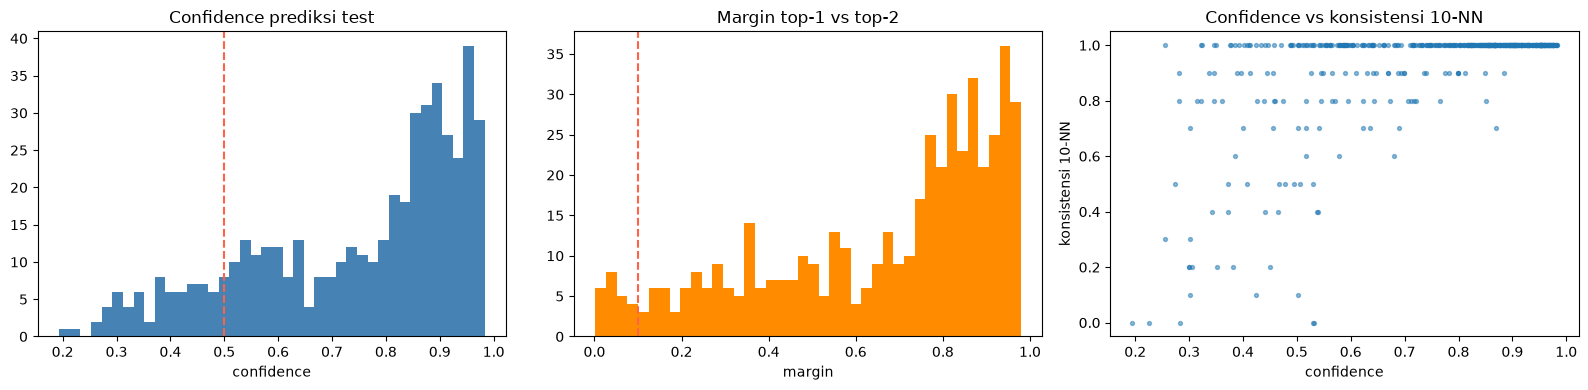

Confidence median: 0.819 | <0.5: 68 | <0.95: 420
Margin < 0.10: 24 gambar | konsistensi 10-NN rata-rata: 0.929 (p10 0.800)

Confidence rata-rata per kelas prediksi:
            size   mean
glass         43  0.675
paper         54  0.699
electronic    48  0.716
metal         64  0.772
plastic      102  0.690
cardboard     61  0.852
textile       36  0.735
foodwaste     72  0.801

8 gambar test paling ambigu:
image_id       pred  confidence  margin_top1_top2  entropy  knn10_consistency
     364 electronic       0.193             0.012    2.019                0.0
     035    textile       0.226             0.004    1.921                0.0
     322      metal       0.255             0.075    1.984                1.0
     216      paper       0.256             0.048    1.910                0.3
     015 electronic       0.274             0.012    1.878                0.5
     001    textile       0.281             0.137    1.954                0.9
     086 electronic       0.281            

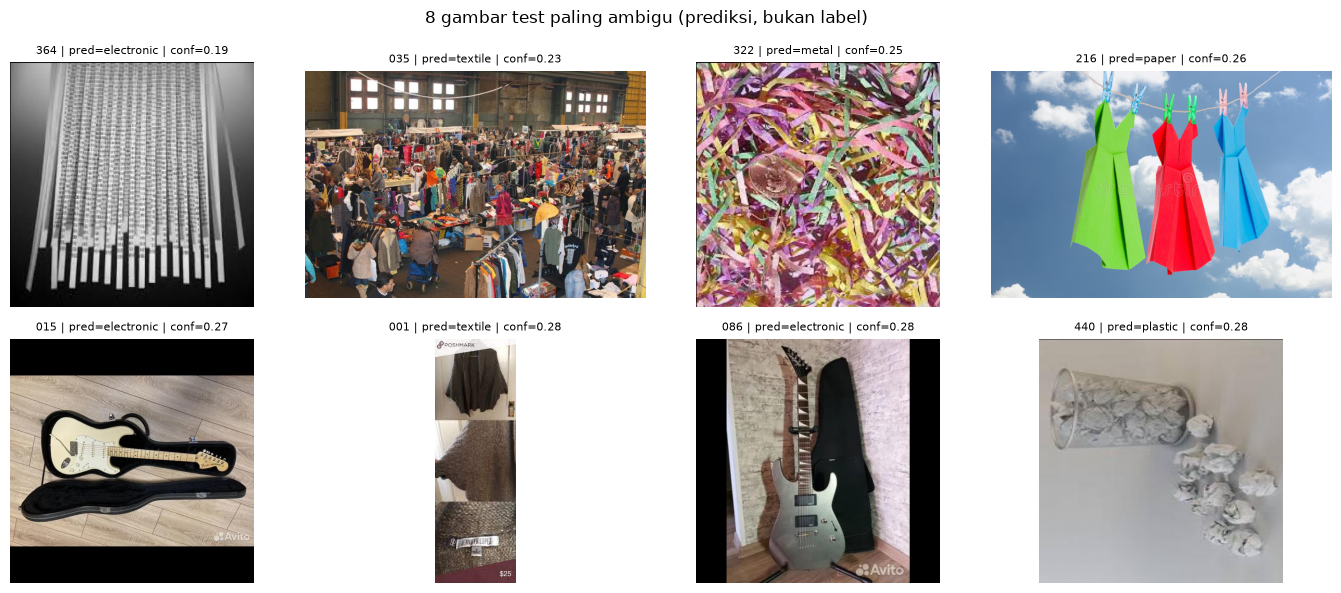

Disimpan: artifacts_nb/test_ambiguity_v1.csv
Batas tafsir: confidence rendah tidak berarti salah; ini hanya peta keraguan model.


In [40]:
# ============================================================
# BAB 11 - ANALISIS AMBIGUITAS TEST (TANPA LABEL)
# ============================================================
sorted_probs = np.sort(mean_test_probs, axis=1)
conf = sorted_probs[:, -1]
margin = sorted_probs[:, -1] - sorted_probs[:, -2]
entropy = -(mean_test_probs * np.log(mean_test_probs + 1e-12)).sum(axis=1)

nn_test_probe = NearestNeighbors(n_neighbors=10, metric="cosine").fit(X_train_comb)
_, nbr_test_probe = nn_test_probe.kneighbors(X_test_comb)
knn_cons = (y_idx[nbr_test_probe] == pred_test_idx[:, None]).mean(axis=1)

ambiguity = pd.DataFrame({
    "image_id": test_df.image_id.astype(str).values,
    "pred": [CLASSES[i] for i in pred_test_idx],
    "confidence": conf,
    "margin_top1_top2": margin,
    "entropy": entropy,
    "knn10_consistency": knn_cons,
})
amb_path = ART_DIR / "test_ambiguity_v1.csv"
ambiguity.to_csv(amb_path, index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(conf, bins=40, color="steelblue"); axes[0].axvline(0.5, color="tomato", ls="--")
axes[0].set_title("Confidence prediksi test"); axes[0].set_xlabel("confidence")
axes[1].hist(margin, bins=40, color="darkorange"); axes[1].axvline(0.1, color="tomato", ls="--")
axes[1].set_title("Margin top-1 vs top-2"); axes[1].set_xlabel("margin")
axes[2].scatter(conf, knn_cons, s=8, alpha=0.5)
axes[2].set_title("Confidence vs konsistensi 10-NN")
axes[2].set_xlabel("confidence"); axes[2].set_ylabel("konsistensi 10-NN")
plt.tight_layout(); plt.show()

per_class_conf = (pd.Series(conf, index=[CLASSES[i] for i in pred_test_idx])
                  .groupby(level=0).agg(["size", "mean"]).reindex(CLASSES))
print(f"Confidence median: {np.median(conf):.3f} | <0.5: {int((conf < 0.5).sum())} | <0.95: {int((conf < 0.95).sum())}")
print(f"Margin < 0.10: {int((margin < 0.10).sum())} gambar | konsistensi 10-NN rata-rata: {knn_cons.mean():.3f} "
      f"(p10 {np.quantile(knn_cons, 0.10):.3f})")
print("\nConfidence rata-rata per kelas prediksi:")
print(per_class_conf.round(3).to_string())
hard = ambiguity.sort_values(["confidence", "knn10_consistency"]).head(8)
print("\n8 gambar test paling ambigu:")
print(hard.round(3).to_string(index=False))

# Tampilkan gambar paling ambigu (hanya test; tidak ada label).
path_by_id = dict(zip(test_df.image_id.astype(str), test_df.path))
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, (_, r) in zip(axes.ravel(), hard.iterrows()):
    ax.imshow(load_image(Path(path_by_id[r.image_id])))
    ax.set_title(f"{r.image_id} | pred={r.pred} | conf={r.confidence:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle("8 gambar test paling ambigu (prediksi, bukan label)")
plt.tight_layout(); plt.show()

print(f"Disimpan: {amb_path.relative_to(ROOT)}")
print("Batas tafsir: confidence rendah tidak berarti salah; ini hanya peta keraguan model.")